# Discrete and smeared stringers: integrally stiffened Technion shells (Weller and Singer 1977; Poorveis and Kabir 2006)

How far is a model with discrete stringers from the smeared-stiffener theory
when the stringers are closely spaced? Weller and Singer [1] tested in axial
compression integrally stringer-stiffened shells of 7075-T6 aluminium alloy,
machined with the stringers outside, and give for each shell the
non-dimensional stringer properties, the buckling load of the linear
smeared-stiffener theory for two simple supports, SS3 ($w = M_x = N_x = v =
0$) and SS4 ($w = M_x = u = v = 0$), and the test load (Table 1, p. 723).
Poorveis and Kabir [2] analysed one of these shells (AS-27M2, their case A)
and a shell of Shen, Zhou and Chen (their case D, shell AB6 of [6], through
[3]) with a
geometrically nonlinear Ritz model, once with discrete and once with smeared
stringers (Table 2, p. 119), and a third shell (their case C, shell DUD-8 of
[5]) under external pressure and combined loading; the twin shell DUD-10
of [5], buckled under combined loading in the reversed sequence, is added.
The pressure is applied as a dead and as a live (follower) load, and case C
and case D are also studied under combined pressure and axial compression,
with the interaction curves of Shen, Zhou and Chen [3] for DUD-8 and DUD-10. This notebook models the shells with discrete
stringers and compares with every one of these values:

- the smeared theory of Block, Card and Mikulas [4] (equation (15), simply
  supported SS3, membrane pre-buckling state), evaluated with the section
  properties of [1] (it reproduces the SS3 loads of [1]) and with the section
  of the discrete model, so that the **discreteness gap** (discrete model
  against smeared theory of the same section) is separated from the effect of
  the section;
- the tests of [1], [3] and [5], and the smeared and discrete values of [2].

Weller and Singer selected the shells for general instability, except the
AS-27 series, whose Koiter parameter $\theta > 0.64$ was chosen on purpose to
study unstable postbuckling of the skin panels between the stringers (p.
722): for these shells Poorveis and Kabir found the discrete value 30 % below
the smeared one and attributed the difference to panel instability (p. 119).

[1] T. Weller and J. Singer, *Experimental studies on the buckling under
axial compression of integrally stringer-stiffened circular cylindrical
shells*, J. Appl. Mech. 44(4), 721-730, 1977, doi:10.1115/1.3424163.

[2] D. Poorveis and M. Z. Kabir, *Buckling of discretely stringer-stiffened
composite cylindrical shells under combined axial compression and external
pressure*, Scientia Iranica 13(2), 113-123, 2006.

[3] H.-S. Shen, P. Zhou and T.-Y. Chen, *Postbuckling analysis of stiffened
cylindrical shells under combined external pressure and axial compression*,
Thin-Walled Struct. 15(1), 43-63, 1993, doi:10.1016/0263-8231(93)90012-Y.

[4] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

[5] H. Abramovich, T. Weller and J. Singer, *Effect of sequence of combined
loading on buckling of stiffened shells*, Exp. Mech. 28(1), 1-13, 1988,
doi:10.1007/BF02328988.

[6] J. Singer and H. Abramovich, *Vibration techniques for definition of
practical boundary conditions in stiffened shells*, AIAA J. 17(7), 762-769,
1979, doi:10.2514/3.61215.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
import bfscplate2d
from blade_cylinder_sector import (BladeCylinderSector, buckling_membrane,
                                   lowest_eigenpairs, axial_nodes,
                                   normalize_phase, W)
from smeared_stiffened_cylinder import buckling_ss

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Shells, geometry and material

Table 1 of [1] (p. 723) gives, for each shell, the skin thickness $h$, $R/h$,
$L/R$, the eccentricity $e_1/h$ of the stringer centroid (printed as $-(e_1/h)$,
$e_1$ being negative outside, Fig. 1), the area parameter $A_1/(bh)$, the
moment of inertia of the stringer about its centroid $I_{11}/(bh^3)$, the
torsion parameter $\eta_{t1} = G_1 I_{t1}/(bD)$ with $D = E h^3/(12(1 -
\nu^2))$, Koiter's parameter $\theta = [12(1 - \nu^2)]^{1/4} (b/2\pi)
(Rh)^{-1/2}$ (nomenclature, p. 722), the SS3 and SS4 loads of the smeared
theory and the test load, in kg (kilogram-force). Material (p. 724): $E =
0.75 \times 10^4$ kg/mm$^2$; $\nu = 0.30$ (p. 722). The stringer spacing $b$
is not printed: it follows from $\theta$, and $2\pi R/b$ gives the number of
stringers $n_s$, an integer within the rounding of $\theta$.

The shells AS-26M1 to AS-26M3 are listed in Table 1 but excluded by the
authors from their summary because of irregular edge effects in the strain
records (footnote b); they are left out here too. For AS-35 the SS4 load is
printed as 460 kg, a misprint: the printed ratio $\rho_{SS4} = 0.610$ gives
$2850/0.610 = 4672$ kg (this value is not used below).

In [2]:
E = 0.75e4  # kg/mm^2, p. 724
nu = 0.30   # p. 722
KGF = 9.80665  # N
# Table 1 of [1], p. 723: h (mm), R/h, L/R, -(e1/h), A1/(bh), I11/(bh^3),
# eta_t1, theta, P_cr SS3, P_cr SS4, P_exp (kg)
TABLE1 = {
    'AS-27M1': (0.195, 618, 0.648, 3.86, 0.760, 2.860, 23.50, 0.807, 4190, 4540, 3600),
    'AS-27M2': (0.204, 591, 0.652, 3.67, 0.717, 2.400, 19.84, 0.789, 4210, 4600, 3300),
    'AS-27M3': (0.202, 597, 0.650, 3.72, 0.729, 2.520, 20.83, 0.793, 4240, 4610, 3920),
    'AS-34': (0.254, 472, 1.080, 2.97, 0.533, 1.080, 5.75, 0.470, 3430, 4750, 2800),
    'AS-35': (0.250, 480, 1.080, 3.04, 0.549, 1.180, 6.11, 0.474, 3390, None, 2850),
}
k4 = (12*(1 - nu**2))**0.25
D_E = 1/(12*(1 - nu**2))  # D/(E h^3)
G = E/(2*(1 + nu))
shells = {}
rows = []
for s, (h, Rh, LR, e, Ab, Ib, eta, theta, P3, P4, Pe) in TABLE1.items():
    R = Rh*h
    L = LR*R
    ns_real = 2*np.pi*R/(theta*2*np.pi*np.sqrt(R*h)/k4)
    ns = int(round(ns_real))
    b = 2*np.pi*R/ns
    A = Ab*b*h
    I = Ib*b*h**3
    J = eta*b*E*D_E*h**3/G
    shells[s] = dict(h=h, R=R, L=L, ns=ns, b=b, A=A, I=I, e=e*h, J=J,
                     P3=P3, P4=P4, Pe=Pe)
    rows.append([s, h, '%.2f' % R, '%.2f' % L, '%.2f (%d)' % (ns_real, ns),
                 '%.3f' % b, '%.4f' % A, '%.4f' % (e*h), '%.4f' % I,
                 '%.4f' % J, P3, P4 or '(4672)', Pe,
                 '%.3f' % (Pe/(2*np.pi*R)), '%.3f' % (Pe*KGF/(2*np.pi*R))])
table(['shell', 'h, mm', 'R, mm', 'L, mm', '2 pi R/b (n_s)', 'b, mm',
       'A_1, mm^2', 'e_1, mm', 'I_11, mm^4', 'I_t1, mm^4', 'SS3, kg',
       'SS4, kg', 'test, kg', 'test N, kg/mm', 'test N, N/mm'], rows)

| shell | h, mm | R, mm | L, mm | 2 pi R/b (n_s) | b, mm | A_1, mm^2 | e_1, mm | I_11, mm^4 | I_t1, mm^4 | SS3, kg | SS4, kg | test, kg | test N, kg/mm | test N, N/mm |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AS-27M1 | 0.195 | 120.51 | 78.09 | 56.00 (56) | 13.521 | 2.0038 | 0.7527 | 0.2867 | 0.5610 | 4190 | 4540 | 3600 | 4.754 | 46.625 |
| AS-27M2 | 0.204 | 120.56 | 78.61 | 56.01 (56) | 13.527 | 1.9786 | 0.7487 | 0.2756 | 0.5425 | 4210 | 4600 | 3300 | 4.356 | 42.721 |
| AS-27M3 | 0.202 | 120.59 | 78.39 | 56.01 (56) | 13.531 | 1.9925 | 0.7514 | 0.2810 | 0.5531 | 4240 | 4610 | 3920 | 5.173 | 50.734 |
| AS-34 | 0.254 | 119.89 | 129.48 | 84.03 (84) | 8.968 | 1.2141 | 0.7544 | 0.1587 | 0.2012 | 3430 | 4750 | 2800 | 3.717 | 36.452 |
| AS-35 | 0.25 | 120.00 | 129.60 | 84.02 (84) | 8.976 | 1.2320 | 0.7600 | 0.1655 | 0.2040 | 3390 | (4672) | 2850 | 3.780 | 37.068 |

**Stringer section.** A rectangle of height $h_s$ and width $t_s$ standing on
the skin has $A_1 = t_s h_s$, $I_{11} = t_s h_s^3/12$ and $e_1 = (h +
h_s)/2$. With $h_s = \sqrt{12 I_{11}/A_1}$ the eccentricity of Table 1 is
reproduced to 0.2 % or better and the torsion constant $I_{t1}$ is that of a
rectangle (Saint-Venant, $\beta\, t_s^3 h_s$), within 1 %: the stringers of
[1] are rectangles, $t_s \times h_s$ (the cutters of [1] leave a curved
skin surface between the stringers, p. 724). The AS-27 stringers are wider
than they are tall.

In [3]:
def rect_J(a, c):
    # Saint-Venant torsion constant of a rectangle a x c
    a, c = max(a, c), min(a, c)
    return c**3*a*(1/3 - 64/np.pi**5*c/a*np.tanh(np.pi*a/(2*c)))


rows = []
for s, d in shells.items():
    d['hs'] = np.sqrt(12*d['I']/d['A'])
    d['ts'] = d['A']/d['hs']
    rows.append([s, '%.3f' % d['ts'], '%.3f' % d['hs'],
                 '%.4f (%+.2f %%)' % ((d['h'] + d['hs'])/2, pct((d['h'] + d['hs'])/2, d['e'])),
                 '%.4f (%+.1f %%)' % (rect_J(d['ts'], d['hs']), pct(rect_J(d['ts'], d['hs']), d['J']))])
table(['shell', 't_s, mm', 'h_s, mm', '(h + h_s)/2 vs e_1, mm', 'J of the rectangle vs I_t1, mm^4'], rows)

| shell | t_s, mm | h_s, mm | (h + h_s)/2 vs e_1, mm | J of the rectangle vs I_t1, mm^4 |
|---|---|---|---|---|
| AS-27M1 | 1.529 | 1.310 | 0.7527 (-0.00 %) | 0.5611 (+0.0 %) |
| AS-27M2 | 1.530 | 1.293 | 0.7485 (-0.03 %) | 0.5458 (+0.6 %) |
| AS-27M3 | 1.532 | 1.301 | 0.7515 (+0.01 %) | 0.5540 (+0.2 %) |
| AS-34 | 0.969 | 1.252 | 0.7532 (-0.15 %) | 0.2019 (+0.3 %) |
| AS-35 | 0.970 | 1.270 | 0.7598 (-0.02 %) | 0.2072 (+1.6 %) |

## Smeared-stiffener theory

Equation (15) of [4] (simply supported SS3, membrane pre-buckling state,
`smeared_stiffened_cylinder.buckling_ss`), minimized over $m = 1 \ldots 12$
and $n = 1 \ldots 60$, with the stringer properties of Table 1 reproduces the
SS3 loads of [1] within 0.1 %: the section and the material are read as
Weller and Singer read them.

The discrete model (below) represents each stringer by a plate strip normal
to the skin, from the middle surface of the skin to the tip of the stringer,
of thickness $t_s$ and width $H_s = h_s + h/2$. As a smeared section this
strip has $A = t_s H_s$, $\bar{z} = H_s/2$, $I_o = t_s H_s^3/3$ about the
middle surface of the skin (it overlaps the skin by $h/2$), and the
twisting stiffness of a Kirchhoff plate strip, $4 D_{66} H_s = G H_s t_s^3/3$,
which is 2 to 3 times $G I_{t1}$ of the rectangle for these squat stringers.
The twisting stiffness enters the general-instability load strongly (the
column "J = 0" shows how much), so the model is run twice: with the plate
strip as it is ("plate J") and with $D_{66}$ of the strip scaled so that $4
D_{66} H_s = G I_{t1}$ ("matched J", the main model). The discreteness gap
is the discrete model against equation (15) for the same strip.

In [4]:
mgrid = np.arange(1, 13)[:, None]
ngrid = np.arange(1, 61)[None, :]


def smeared(d, A, z, Io, J):
    N = buckling_ss(d['R'], d['L'], d['h'], E, nu, d['b'], A, z, Io, J, mgrid, ngrid)
    i, j = np.unravel_index(np.argmin(N), N.shape)
    return N[i, j], (int(mgrid[i, 0]), int(ngrid[0, j]))


rows = []
for s, d in shells.items():
    d['Hs'] = d['hs'] + d['h']/2
    d['Jplate'] = d['Hs']*d['ts']**3/3
    Ws = (d['A'], d['e'], d['I'] + d['A']*d['e']**2)
    Ps = (d['ts']*d['Hs'], d['Hs']/2, d['ts']*d['Hs']**3/3)
    d['sm_W'] = smeared(d, *Ws, d['J'])
    d['sm_W_J0'] = smeared(d, *Ws, 0.)
    d['sm_P_J'] = smeared(d, *Ps, d['J'])
    d['sm_P_Jp'] = smeared(d, *Ps, d['Jplate'])
    N3 = d['P3']/(2*np.pi*d['R'])
    rows.append([s, '%.3f' % N3,
                 '%.3f %s, %+.2f %%' % (d['sm_W'][0], d['sm_W'][1], pct(d['sm_W'][0], N3)),
                 '%.3f, %+.1f %%' % (d['sm_W_J0'][0], pct(d['sm_W_J0'][0], N3)),
                 '%.3f %s, %+.1f %%' % (d['sm_P_J'][0], d['sm_P_J'][1], pct(d['sm_P_J'][0], N3)),
                 '%.3f %s, %+.1f %%' % (d['sm_P_Jp'][0], d['sm_P_Jp'][1], pct(d['sm_P_Jp'][0], N3)),
                 '%.2f' % (d['J']/d['Jplate'])])
table(['shell', 'SS3 of [1], kg/mm', 'Eq. (15), section of [1]', 'same, J = 0',
       'Eq. (15), plate strip, matched J', 'Eq. (15), plate strip, plate J',
       'I_t1/J_plate'], rows)

| shell | SS3 of [1], kg/mm | Eq. (15), section of [1] | same, J = 0 | Eq. (15), plate strip, matched J | Eq. (15), plate strip, plate J | I_t1/J_plate |
|---|---|---|---|---|---|---|
| AS-27M1 | 5.534 | 5.540 (1, 13), +0.11 % | 3.859, -30.3 % | 5.555 (1, 13), +0.4 % | 7.998 (1, 11), +44.5 % | 0.33 |
| AS-27M2 | 5.558 | 5.557 (1, 13), -0.01 % | 3.965, -28.7 % | 5.574 (1, 13), +0.3 % | 8.037 (1, 11), +44.6 % | 0.33 |
| AS-27M3 | 5.596 | 5.589 (1, 13), -0.11 % | 3.959, -29.2 % | 5.607 (1, 13), +0.2 % | 8.068 (1, 11), +44.2 % | 0.33 |
| AS-34 | 4.553 | 4.547 (1, 11), -0.14 % | 4.002, -12.1 % | 4.582 (1, 11), +0.6 % | 5.171 (1, 11), +13.6 % | 0.48 |
| AS-35 | 4.496 | 4.491 (1, 11), -0.11 % | 3.940, -12.4 % | 4.527 (1, 11), +0.7 % | 5.122 (1, 11), +13.9 % | 0.48 |

## Model with discrete stringers

`BladeCylinderSector`: a sector of one stringer pitch with cyclic symmetry
(each harmonic $n$ solved separately; the harmonic $n$ contains the waves
$n + j n_s$ coupled by the stringers, and $n = n_s/2$ the local buckling of
the skin between the stringers with one half-wave per bay), the skin meshed
with `BFSCCylinderSanders` and the stringer with `BFSCPlate2D`, tied along
its root. Simply supported SS3 ends ($v = w = 0$ on the skin and the
stringer, $u$ free) and the membrane pre-buckling state of a uniform axial
strain (`buckling_membrane(model, 'SS', n)`), as in the smeared theory. The
lowest load over all harmonics $n = 1 \ldots n_s/2$ is the critical one.

In [5]:
def build(d, mesh, J='matched'):
    nx, nbay, nh = mesh
    model = BladeCylinderSector(R=d['R'], L=d['L'], h=d['h'], E=E, nu=nu,
                                rho=0., nstringers=d['ns'], nx=nx, nbay=nbay,
                                bs=d['ts'], Hs=d['Hs'], side='external', nh=nh)
    if J == 'matched':
        ABD = np.array(model.str_prop.ABD, dtype=float)
        ABD[5, 5] *= d['J']/d['Jplate']
        for plate in model.str_elements:
            plate.ABD = ABD
    return model


def scan(d, mesh, J='matched'):
    model = build(d, mesh, J)
    out = {}
    for n in range(1, d['ns']//2 + 1):
        N, X = buckling_membrane(model, 'SS', n, k=1)
        out[n] = (N[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    n = min(out, key=lambda n: out[n][0])
    return model, out, n

## Mesh convergence

Three meshes `(nx, nbay, nh)`: nodes along $x$, skin elements across the
stringer pitch, stringer elements along its height. The local modes of the
AS-27 shells have about nine axial half-waves and need the finer meshes.

In [6]:
MESHES = [(17, 8, 3), (25, 12, 4), (37, 16, 5)]
t0 = time.time()
rows = []
for s, d in shells.items():
    prev = None
    for mesh in MESHES:
        model, out, n = scan(d, mesh)
        N, m, _ = out[n]
        rows.append([s, mesh, model.Nr, '%.4f' % N, '(%d, %d)' % (m, n),
                     '' if prev is None else '%+.2f %%' % pct(N, prev)])
        prev = N
table(['shell', 'mesh', 'dofs per harmonic', 'N_cr, kg/mm', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | mesh | dofs per harmonic | N_cr, kg/mm | (m, n) | change |
|---|---|---|---|---|---|
| AS-27M1 | (17, 8, 3) | 1904 | 4.1524 | (9, 28) |  |
| AS-27M1 | (25, 12, 4) | 4050 | 4.1376 | (9, 28) | -0.36 % |
| AS-27M1 | (37, 16, 5) | 7844 | 4.1342 | (9, 28) | -0.08 % |
| AS-27M2 | (17, 8, 3) | 1904 | 4.5601 | (9, 28) |  |
| AS-27M2 | (25, 12, 4) | 4050 | 4.5439 | (9, 28) | -0.35 % |
| AS-27M2 | (37, 16, 5) | 7844 | 4.5403 | (9, 28) | -0.08 % |
| AS-27M3 | (17, 8, 3) | 1904 | 4.4723 | (9, 28) |  |
| AS-27M3 | (25, 12, 4) | 4050 | 4.4564 | (9, 28) | -0.36 % |
| AS-27M3 | (37, 16, 5) | 7844 | 4.4528 | (9, 28) | -0.08 % |
| AS-34 | (17, 8, 3) | 1904 | 4.5452 | (1, 11) |  |
| AS-34 | (25, 12, 4) | 4050 | 4.5318 | (1, 11) | -0.30 % |
| AS-34 | (37, 16, 5) | 7844 | 4.5258 | (1, 11) | -0.13 % |
| AS-35 | (17, 8, 3) | 1904 | 4.4897 | (1, 11) |  |
| AS-35 | (25, 12, 4) | 4050 | 4.4763 | (1, 11) | -0.30 % |
| AS-35 | (37, 16, 5) | 7844 | 4.4703 | (1, 11) | -0.13 % |

832 s


## Discrete against smeared stringers and the tests

The finest mesh, both twisting stiffnesses of the strip. $\bar{N} = P/(2\pi
R)$ in kg/mm (multiply by 9.807 for N/mm); "gap" is the discrete model
against equation (15) for the same strip and twisting stiffness.

In [7]:
t0 = time.time()
res = {}
for s, d in shells.items():
    for J in ('matched', 'plate'):
        res[(s, J)] = scan(d, MESHES[-1], J)
rows = []
for s, d in shells.items():
    N3, Ne = d['P3']/(2*np.pi*d['R']), d['Pe']/(2*np.pi*d['R'])
    for J, sm in (('matched', d['sm_P_J']), ('plate', d['sm_P_Jp'])):
        model, out, n = res[(s, J)]
        N, m, _ = out[n]
        rows.append([s, J, '%.3f (%d, %d)' % (N, m, n), '%.3f %s' % sm,
                     '**%+.1f %%**' % pct(N, sm[0]), '%.3f' % N3, '%+.1f %%' % pct(N, N3),
                     '%.3f' % Ne, '%+.1f %%' % pct(N, Ne)])
table(['shell', 'J', 'discrete N (m, n)', 'Eq. (15), same strip', 'gap',
       'SS3 of [1]', 'vs SS3', 'test', 'vs test'], rows)
print('%.0f s' % (time.time() - t0))

| shell | J | discrete N (m, n) | Eq. (15), same strip | gap | SS3 of [1] | vs SS3 | test | vs test |
|---|---|---|---|---|---|---|---|---|
| AS-27M1 | matched | 4.134 (9, 28) | 5.555 (1, 13) | **-25.6 %** | 5.534 | -25.3 % | 4.754 | -13.0 % |
| AS-27M1 | plate | 4.172 (9, 28) | 7.998 (1, 11) | **-47.8 %** | 5.534 | -24.6 % | 4.754 | -12.2 % |
| AS-27M2 | matched | 4.540 (9, 28) | 5.574 (1, 13) | **-18.5 %** | 5.558 | -18.3 % | 4.356 | +4.2 % |
| AS-27M2 | plate | 4.589 (9, 28) | 8.037 (1, 11) | **-42.9 %** | 5.558 | -17.4 % | 4.356 | +5.3 % |
| AS-27M3 | matched | 4.453 (9, 28) | 5.607 (1, 13) | **-20.6 %** | 5.596 | -20.4 % | 5.173 | -13.9 % |
| AS-27M3 | plate | 4.498 (9, 28) | 8.068 (1, 11) | **-44.2 %** | 5.596 | -19.6 % | 5.173 | -13.1 % |
| AS-34 | matched | 4.526 (1, 11) | 4.582 (1, 11) | **-1.2 %** | 4.553 | -0.6 % | 3.717 | +21.8 % |
| AS-34 | plate | 5.062 (1, 11) | 5.171 (1, 11) | **-2.1 %** | 4.553 | +11.2 % | 3.717 | +36.2 % |
| AS-35 | matched | 4.470 (1, 11) | 4.527 (1, 11) | **-1.2 %** | 4.496 | -0.6 % | 3.780 | +18.3 % |
| AS-35 | plate | 5.010 (1, 11) | 5.122 (1, 11) | **-2.2 %** | 4.496 | +11.4 % | 3.780 | +32.6 % |

1214 s


**Critical load of each harmonic.** The AS-27 shells buckle locally, in the
harmonic $n = n_s/2 = 28$ (one half-wave of the skin per bay); AS-34 and
AS-35 in a general mode with one axial half-wave.

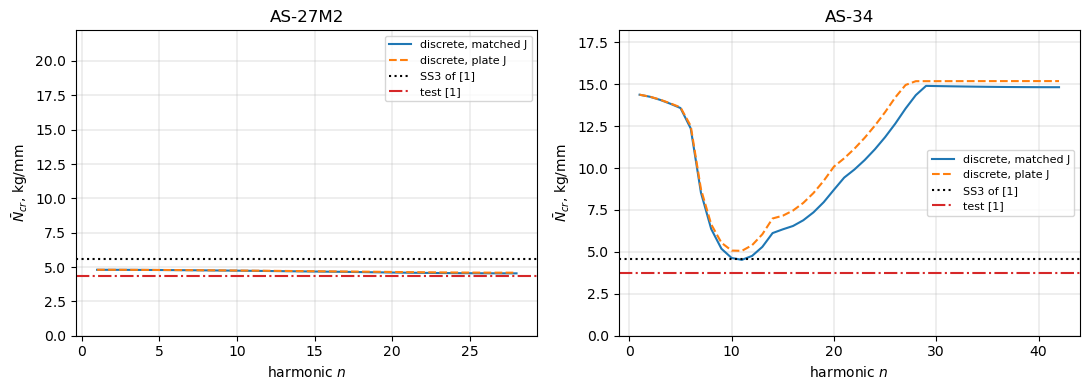

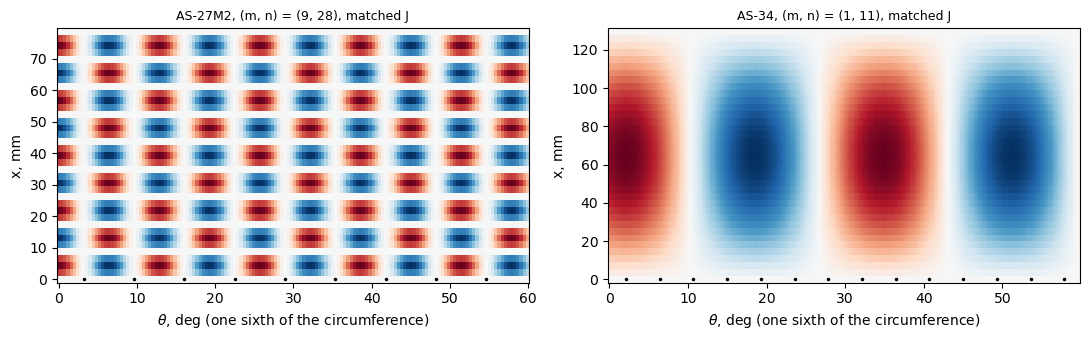

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axes, ('AS-27M2', 'AS-34')):
    d = shells[s]
    for J, style in (('matched', 'C0-'), ('plate', 'C1--')):
        out = res[(s, J)][1]
        ns = sorted(out)
        ax.plot(ns, [out[n][0] for n in ns], style, label='discrete, %s J' % J)
    ax.axhline(d['P3']/(2*np.pi*d['R']), color='k', ls=':', label='SS3 of [1]')
    ax.axhline(d['Pe']/(2*np.pi*d['R']), color='C3', ls='-.', label='test [1]')
    ax.set_ylim(0, 4*d['P3']/(2*np.pi*d['R']))
    ax.set_xlabel('harmonic $n$')
    ax.set_ylabel(r'$\bar{N}_{cr}$, kg/mm')
    ax.set_title(s)
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, s in zip(axes, ('AS-27M2', 'AS-34')):
    model, out, n = res[(s, 'matched')]
    w = normalize_phase(model.skin_field(out[n][2], W))
    th, wf = model.full_circumference(w, n)
    sel = th <= 2*np.pi/6
    ax.pcolormesh(np.degrees(th[sel]), model.xlin, wf[:, sel]/np.abs(wf).max(),
                  cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
    pos = (np.arange(model.nstringers) + 0.5)*model.phi
    pos = pos[pos <= 2*np.pi/6]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_xlabel(r'$\theta$, deg (one sixth of the circumference)')
    ax.set_ylabel('x, mm')
    ax.set_title('%s, (m, n) = (%d, %d), matched J' % (s, out[n][1], n), fontsize=9)
plt.tight_layout()
plt.show()

## The cases of Poorveis and Kabir

Table 1 of [2] (p. 119) gives the shells of Table 2 with the same
non-dimensional parameters ($b$ here is the spacing $b_1 = 2\pi R/n_s$; $D$
that of the skin), $E = 7500$ kg/mm$^2$, $\nu = 0.3$, classical simple
supports, outside stringers. Case A is AS-27M2 of [1] (same $h$, $R$, $L$,
section; the test 4.356 kg/mm is 3300 kg of [1]); case B is cylinder 1 of
Card and Jones (1966), already modelled in the notebook
`card1966_stiffened_cylinder_buckling.ipynb` (its "test" value is the smeared
linear value of Card and Jones, footnote b of Table 2); case C is loaded by
external pressure (next section); case D, with 85 stringers, is
modelled below. The values of [2] come from a geometrically nonlinear
analysis with pre-buckling deformations (Donnell kinematics, first-order
shear deformation of skin and stringers, Lagrange multipliers at the
interface), the stringer section from the same parameters.

In [9]:
# Table 1 of [2], p. 119: L, R, h (mm), n_s, A1/(b1 h), e1/h, I1/(b h^3), G1 J1/(b D)
POORVEIS_T1 = {'A': (78.618, 120.56, 0.204, 56, 0.717, 3.670, 2.400, 19.839),
               'D': (130.00, 120.10, 0.254, 85, 0.590, 3.420, 1.680, 6.563)}
# Table 2 of [2], p. 119 (kg/mm): test, smeared (nonlinear), discrete (nonlinear)
POORVEIS_T2 = {'A': (4.356, 6.110, 4.250), 'B': (20.43, 20.39, 21.45),
               'D': (5.334, 5.370, 5.450)}
d = {}
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_T1['D']
b = 2*np.pi*R/ns
d = dict(h=h, R=R, L=L, ns=ns, b=b, A=Ab*b*h, I=Ib*b*h**3, e=e*h,
         J=eta*b*E*D_E*h**3/G)
d['hs'] = np.sqrt(12*d['I']/d['A'])
d['ts'] = d['A']/d['hs']
d['Hs'] = d['hs'] + h/2
d['Jplate'] = d['Hs']*d['ts']**3/3
print('case D: theta = %.3f, t_s = %.3f mm, h_s = %.3f mm, (h + h_s)/2 = %.4f mm (e_1 = %.4f mm), '
      'J of the rectangle %.4f mm^4 (I_t1 = %.4f)'
      % (k4*b/(2*np.pi*np.sqrt(R*h)), d['ts'], d['hs'], (h + d['hs'])/2, d['e'],
         rect_J(d['ts'], d['hs']), d['J']))
d['sm_W'] = smeared(d, d['A'], d['e'], d['I'] + d['A']*d['e']**2, d['J'])
Ps = (d['ts']*d['Hs'], d['Hs']/2, d['ts']*d['Hs']**3/3)
d['sm_P_J'] = smeared(d, *Ps, d['J'])
d['sm_P_Jp'] = smeared(d, *Ps, d['Jplate'])
shells['D'] = d
t0 = time.time()
rows = []
for mesh in [(25, 12, 4), (37, 16, 5)]:
    for J in ('matched', 'plate'):
        model, out, n = scan(d, mesh, J)
        res[('D', J)] = (model, out, n)
        rows.append([mesh, J, '%.3f (%d, %d)' % (out[n][0], out[n][1], n)])
table(['mesh', 'J', 'discrete N, kg/mm (m, n)'], rows)
print('%.0f s' % (time.time() - t0))

case D: theta = 0.465, t_s = 0.896 mm, h_s = 1.485 mm, (h + h_s)/2 = 0.8694 mm (e_1 = 0.8687 mm), J of the rectangle 0.2227 mm^4 (I_t1 = 0.2273)


| mesh | J | discrete N, kg/mm (m, n) |
|---|---|---|
| (25, 12, 4) | matched | 4.995 (1, 11) |
| (25, 12, 4) | plate | 5.390 (1, 11) |
| (37, 16, 5) | matched | 4.988 (1, 11) |
| (37, 16, 5) | plate | 5.384 (1, 11) |

377 s


In [10]:
rows = []
for case, s in (('A', 'AS-27M2'), ('D', 'D')):
    test, sm2, di2 = POORVEIS_T2[case]
    dd = shells[s]
    Nm = res[(s, 'matched')][1][res[(s, 'matched')][2]][0]
    Np = res[(s, 'plate')][1][res[(s, 'plate')][2]][0]
    rows.append([case, test, sm2, di2, '%+.1f %%' % pct(di2, sm2),
                 '%.3f' % dd['sm_W'][0], '%.3f (%+.1f %%)' % (dd['sm_P_J'][0], pct(Nm, dd['sm_P_J'][0])),
                 '%.3f' % Nm, '%+.1f %%' % pct(Nm, test), '%+.1f %%' % pct(Nm, di2), '%+.1f %%' % pct(Nm, sm2),
                 '%.3f' % Np])
table(['case', 'test', 'smeared [2]', 'discrete [2]', 'discrete vs smeared [2]',
       'Eq. (15), section of [2]', 'Eq. (15), strip, matched J (gap)', 'discrete, matched J',
       'vs test', 'vs discrete [2]', 'vs smeared [2]', 'discrete, plate J'], rows)

| case | test | smeared [2] | discrete [2] | discrete vs smeared [2] | Eq. (15), section of [2] | Eq. (15), strip, matched J (gap) | discrete, matched J | vs test | vs discrete [2] | vs smeared [2] | discrete, plate J |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A | 4.356 | 6.11 | 4.25 | -30.4 % | 5.557 | 5.574 (-18.5 %) | 4.540 | +4.2 % | +6.8 % | -25.7 % | 4.589 |
| D | 5.334 | 5.37 | 5.45 | +1.5 % | 5.018 | 5.052 (-1.3 %) | 4.988 | -6.5 % | -8.5 % | -7.1 % | 5.384 |

## Case C of Poorveis and Kabir: external pressure (shell DUD-8 of [5])

Case C of [2] (Table 1, p. 119: 84 outside stringers, $L = 200$ mm, $R =
120.27$ mm, $h = 0.249$ mm, $A_1/(b_1 h) = 0.666$, $e_1/h = 4.030$, $I_1/(b
h^3) = 2.770$, $G_1 J_1/(bD) = 7.505$) is the shell DUD-8 of Abramovich,
Weller and Singer [5]: Table 1 of [5] (p. 2) gives for DUD-8 $h = 0.249$ mm,
$L = 200$ mm, $R/h = 483$ ($R = 120.27$ mm), $b_1/h = 36.15$, $A_1/(b_1 h) =
0.666$, $I_1/(b_1 h^3) = 2.77$, $e_1/h = -4.03$, 84 integral external
stringers, 7075-T6, $E = 7.5 \times 10^4$ MPa, $\nu = 0.3$ (the footnote
also prints $R = 120.12$ mm and $b_1 = 8.985$ mm for DUD-8 to DUD-11; $R/h$
and $b_1/h$ give 120.27 mm and 9.00 mm, the values used by [2] and here).
The torsion parameter $G_1 J_1/(bD)$ is not in Table 1 of [5].

The ends were nominal simple supports, found with the vibration correlation
technique to be between SS-3 and SS-4 (p. 3, p. 8). Table 4 of [5] (p. 9)
gives for DUD-8 the tests and the predictions of [5] for SS3 and SS4 ends and
for the equivalent end springs of the vibration correlation technique:

| run | load | test $(n/m)$ | SS3 $(n/m)$ | SS4 $(n/m)$ | equivalent springs $(n/m)$ |
|---|---|---|---|---|---|
| 1 | external pressure, kPa | 13.55 (10/1) | 13.3 (11/1) | 16.7 (13/1) | 14.6 (11/1) |
| 2 | pressure, kPa, at $P = 4$ kN | 12.3 (9/1) | 12.0 (11/1) | 15.8 (13/1) | 14.2 (12/1) |
| 3 | pressure, kPa, at $P = 8$ kN | 11.10 (9/1) | 10.7 (11/1) | 14.8 (12/1) | 13.3 (12/1) |
| 4 | axial compression, kN | 32 (7/1) | 33.14 (9/1) | 54.05 (10/1) | 41.80 (10/1) |

Table 2 of [2] (p. 119) lists runs 1 and 3 as C1 and C2, with the
nonlinear smeared and discrete values of [2]:

| row | test | smeared [2] $(M, n)$ | discrete [2] $(M, n, N)$ |
|---|---|---|---|
| C1 | 0.001355 (1, 10) | 0.001316 (10, 11) | 0.001480 (10, 11, 10) |
| C2, $P = 1.0587$ kg/mm | 0.001110 (1, 9) | 0.001095 (10, 11) | 0.001270 (10, 10, 10) |

**Units.** The values of [2] are those of [5] with 1 kg = 10 N: 13.55 kPa =
0.001355 kg/mm$^2$, $P = 8000/(2\pi \times 120.27)/10 = 1.0587$ kg/mm, and $E
= 7500$ kg/mm$^2$ is the 75 GPa of [5]. The model below uses these units (mm,
$E = 7500$); a pressure $q$ in them is $10^4 q$ kPa, which the tables print.
(The other shells of this notebook have $E = 7500$ kg/mm$^2$ with kg the
kilogram-force, [1]; only the ratio of load to $E$ matters.)

**Lateral or hydrostatic pressure.** [2] writes the external work of a radial
dead pressure $q_D$, adds that "for hydrostatic pressure, $P$ is related to
$q_D$ ($P = R q_D/2$)" and gives the load stiffness of a live pressure (p.
117), without saying which was used for case C. The text of [5] says only
"external pressure"; its Fig. 1 (p. 3) draws the pressure $p$ inside the
pressure vessel on the shell wall and on the bottom end plate, that is, closed
ends with the axial end load of hydrostatic pressure; whether the axial load
$P$ of the load cell includes this end load is not said. Both are computed, first
as dead loads (a live variant follows the results): **lateral** ($\bar{N}_y = q R$, $\bar{N}_x = 0$) and
**hydrostatic** ($\bar{N}_x = q R/2$ in addition); the axial load $P$ of
runs 2 and 3 is added to $\bar{N}_x$.

**Smeared theory.** Equation (15) of [4] (p. 12) holds for "any specified
combination of axial and circumferential loading" and "can be used to
investigate buckling under axial compression or under hydrostatic or
lateral pressure, or to investigate interactions between axial compression
and lateral pressure":

$$\left(\frac{m \pi}{L}\right)^2 \bar{N}_x + \left(\frac{n}{R}\right)^2
\bar{N}_y = A_{33} + \ldots$$

the right-hand side being `buckling_ss` times $(m\pi/L)^2$, $\bar{N}_x$ and
$\bar{N}_y$ positive in compression, from a uniform normal stress in skin and
stringers (p. 8); without rings the skin carries the hoop force. With
$\bar{N}_y = q R$ and $\bar{N}_x = P/(2\pi R) + \kappa q R/2$ ($\kappa = 0$
lateral, 1 hydrostatic):

$$q = \min_{m, n} \frac{\textrm{rhs} - (m\pi/L)^2 P/(2\pi R)}{\kappa
(m\pi/L)^2 R/2 + (n/R)^2 R}$$

**Discrete model.** The sector of the axial cases with the membrane
pre-buckling state of equation (15): the hoop force $N_{yy} = -q R$ in the
skin (`update_KG_constant_stress` of `BFSCCylinderSanders`), no hoop force in
the stringer plate, and for $\bar{N}_x$ the uniform axial strain of
`KG_membrane` (skin and stringer, with the in-plane terms of the stringer)
scaled to the force per unit circumference. The fixed load $P$ is added to
the stiffness, $(\boldsymbol{K} + \bar{N}_P \boldsymbol{K}_{G,x})
\boldsymbol{x} = q (-\boldsymbol{K}_{G,q}) \boldsymbol{x}$, so that the
eigenvalue is the pressure. The membrane state, rather than a linear static
pre-buckling state, is chosen because it is the state of equation (15): the
comparison with the smeared theory is like for like, as for the axial cases.
A linear static state would add the bending of the skin near the SS3 ends,
where $w = 0$ holds back the radial contraction under pressure; [2] includes
it, with the nonlinear pre-buckling deformation. The torsion constant is
$I_{t1}$ from $G_1 J_1/(bD)$ of [2].

In [11]:
# Table 1 of [2], p. 119 (= DUD-8, Table 1 of [5], p. 2)
POORVEIS_T1['C'] = (200.00, 120.27, 0.249, 84, 0.666, 4.030, 2.770, 7.505)
KPA = 1e4  # kPa per unit pressure of the model (1 kg = 10 N, mm)
# Table 4 of [5], p. 9 (kPa): test, SS3, SS4, equivalent springs; axial load P in kN
DUD8 = {1: (0., 13.55, 13.3, 16.7, 14.6), 2: (4., 12.3, 12.0, 15.8, 14.2),
        3: (8., 11.10, 10.7, 14.8, 13.3)}
DUD8_AXIAL = (32., 33.14, 54.05, 41.80)  # kN, run 4
# Table 2 of [2], p. 119 (units of the model): test, smeared (nonlinear), discrete (nonlinear)
POORVEIS_C = {1: (0.001355, 0.001316, 0.001480), 3: (0.001110, 0.001095, 0.001270)}
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_T1['C']
b = 2*np.pi*R/ns
dc = dict(h=h, R=R, L=L, ns=ns, b=b, A=Ab*b*h, I=Ib*b*h**3, e=e*h,
          J=eta*b*E*D_E*h**3/G)
dc['hs'] = np.sqrt(12*dc['I']/dc['A'])
dc['ts'] = dc['A']/dc['hs']
dc['Hs'] = dc['hs'] + h/2
dc['Jplate'] = dc['Hs']*dc['ts']**3/3
shells['C'] = dc


def Nbar(P_kN):
    # axial force per unit circumference, units of the model
    return P_kN*1e3/(2*np.pi*R)/10


LOADS = [(run, load, kappa, Nbar(DUD8[run][0])) for run in DUD8
         for load, kappa in (('lateral', 0), ('hydrostatic', 1))]
print('case C: b = %.3f mm, theta = %.3f, t_s = %.3f mm, h_s = %.3f mm, (h + h_s)/2 = %.4f mm (e_1 = %.4f mm), '
      'J of the rectangle %.4f mm^4 (I_t1 = %.4f), J_plate = %.4f mm^4; P = 8 kN: %.4f kg/mm'
      % (b, k4*b/(2*np.pi*np.sqrt(R*h)), dc['ts'], dc['hs'], (h + dc['hs'])/2, dc['e'],
         rect_J(dc['ts'], dc['hs']), dc['J'], dc['Jplate'], Nbar(8.)))


def smeared_q(d, A, z, Io, J, kappa, P):
    # equation (15) of [4] with N_y = q R and N_x = P + kappa q R/2
    am = mgrid*np.pi/d['L']
    bn = ngrid/d['R']
    rhs = buckling_ss(d['R'], d['L'], d['h'], E, nu, d['b'], A, z, Io, J, mgrid, ngrid)*am**2
    q = (rhs - am**2*P)/(kappa*am**2*d['R']/2 + bn**2*d['R'])
    i, j = np.unravel_index(np.argmin(q), q.shape)
    return q[i, j], (int(mgrid[i, 0]), int(ngrid[0, j]))


Wsec = (dc['A'], dc['e'], dc['I'] + dc['A']*dc['e']**2)
Psec = (dc['ts']*dc['Hs'], dc['Hs']/2, dc['ts']*dc['Hs']**3/3)
smC = {}
rows = []
for run, load, kappa, P in LOADS:
    smC[(run, load)] = {'W': smeared_q(dc, *Wsec, dc['J'], kappa, P),
                        'W_J0': smeared_q(dc, *Wsec, 0., kappa, P),
                        'matched': smeared_q(dc, *Psec, dc['J'], kappa, P),
                        'plate': smeared_q(dc, *Psec, dc['Jplate'], kappa, P)}
    s = smC[(run, load)]
    P_kN, test, ss3 = DUD8[run][:3]
    qW = KPA*s['W'][0]
    rows.append([run, P_kN, load, '%.2f %s' % (qW, s['W'][1]), '%.2f' % (KPA*s['W_J0'][0]),
                 '%.2f %s' % (KPA*s['matched'][0], s['matched'][1]), '%.2f' % (KPA*s['plate'][0]),
                 ss3, '%+.1f %%' % pct(qW, ss3), test, '%+.1f %%' % pct(qW, test)])
table(['run', 'P, kN', 'pressure', 'Eq. (15), section of [2], kPa (m, n)', 'same, J = 0',
       'Eq. (15), strip, matched J', 'Eq. (15), strip, plate J', 'SS3 of [5]',
       'section of [2] vs SS3 of [5]', 'test [5]', 'section of [2] vs test'], rows)
sma = {k: smeared(dc, *sec, J) for k, sec, J in (('W', Wsec, dc['J']), ('matched', Psec, dc['J']),
                                                 ('plate', Psec, dc['Jplate']))}
kN = 2*np.pi*R*10/1e3  # kN per unit axial force per unit circumference
print('run 4, axial compression, Eq. (15): section of [2] %.2f kN %s (SS3 of [5] %.2f kN, %+.1f %%; test %.0f kN), '
      'strip matched J %.2f kN, plate J %.2f kN'
      % (kN*sma['W'][0], sma['W'][1], DUD8_AXIAL[1], pct(kN*sma['W'][0], DUD8_AXIAL[1]), DUD8_AXIAL[0],
         kN*sma['matched'][0], kN*sma['plate'][0]))

case C: b = 8.996 mm, theta = 0.476, t_s = 0.848 mm, h_s = 1.759 mm, (h + h_s)/2 = 1.0041 mm (e_1 = 1.0035 mm), J of the rectangle 0.2498 mm^4 (I_t1 = 0.2482), J_plate = 0.3830 mm^4; P = 8 kN: 1.0587 kg/mm


| run | P, kN | pressure | Eq. (15), section of [2], kPa (m, n) | same, J = 0 | Eq. (15), strip, matched J | Eq. (15), strip, plate J | SS3 of [5] | section of [2] vs SS3 of [5] | test [5] | section of [2] vs test |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | 13.38 (1, 11) | 11.75 | 13.42 (1, 11) | 14.31 | 13.3 | +0.6 % | 13.55 | -1.3 % |
| 1 | 0.0 | hydrostatic | 13.18 (1, 11) | 11.57 | 13.23 (1, 11) | 14.10 | 13.3 | -0.9 % | 13.55 | -2.7 % |
| 2 | 4.0 | lateral | 12.08 (1, 11) | 10.45 | 12.12 (1, 11) | 13.01 | 12.0 | +0.7 % | 12.3 | -1.8 % |
| 2 | 4.0 | hydrostatic | 11.90 (1, 11) | 10.30 | 11.95 (1, 11) | 12.82 | 12.0 | -0.8 % | 12.3 | -3.2 % |
| 3 | 8.0 | lateral | 10.78 (1, 11) | 9.15 | 10.83 (1, 11) | 11.71 | 10.7 | +0.8 % | 11.1 | -2.9 % |
| 3 | 8.0 | hydrostatic | 10.62 (1, 11) | 9.02 | 10.67 (1, 11) | 11.54 | 10.7 | -0.7 % | 11.1 | -4.3 % |

run 4, axial compression, Eq. (15): section of [2] 34.04 kN (1, 9) (SS3 of [5] 33.14 kN, +2.7 %; test 32 kN), strip matched J 34.30 kN, plate J 36.13 kN


The section of [2] is again a rectangle (first line: $e_1$ and $I_{t1}$
checked). Equation (15) with the section of [2] is the linear smeared
counterpart of the SS3 predictions of [5]; the strip columns are the
references of the discrete model.

In [12]:
def KG_hoop(model):
    # geometric stiffness of the hoop force N_yy = -R (per unit pressure) in the skin
    p, w = model.points, model.weights

    def skin(shell, k, r, c, v):
        shell.init_k_KG = k
        model._sk.update_KG_constant_stress(shell, p, w, r, c, v, 0., -model.R, 0.)

    def stringer(plate, k, r, c, v):
        pass  # no hoop force in the stringer plate
    return model._assemble(skin, model._sk.KG_SPARSE_SIZE, stringer,
                           bfscplate2d.KG_SPARSE_SIZE)


def buckling_pressure(model, n, kappa, P, k=1):
    # harmonic n, SS3 ends: (K + P KGx) x = q (-KGq) x, KGq = KG_hoop + kappa R/2 KGx,
    # KGx the axial membrane state of a unit force per unit circumference
    if not hasattr(model, '_KGx'):
        eps = -1e-3
        model._KGx = model.KG_membrane(eps)/(model.E*abs(eps)*model.area()/(2*np.pi*model.R))
        model._KGh = KG_hoop(model)
    Zn = model.Z(n, free_axial=True)
    K = Zn.conj().T @ model.KC0() @ Zn
    if P:
        K = K + P*(Zn.conj().T @ model._KGx @ Zn)
    KGq = Zn.conj().T @ (model._KGh + kappa*model.R/2*model._KGx) @ Zn
    K, KGq = K.tocsr(), KGq.tocsr()
    bu = ~model.constrained('SS')
    q, X = lowest_eigenpairs(K[bu][:, bu], -KGq[bu][:, bu], k)
    ur = np.zeros((model.Nr, X.shape[1]), dtype=X.dtype)
    ur[bu] = X
    return q, Zn @ ur


def scan_pressure(model, kappa, P):
    out = {}
    for n in range(1, model.nstringers//2 + 1):
        q, X = buckling_pressure(model, n, kappa, P)
        out[n] = (q[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    n = min(out, key=lambda n: out[n][0])
    return out, n

**Convergence** (matched $J$, the six pressure loadings; every harmonic
$n = 1 \ldots 42$). The modes have one axial half-wave over the longer
shell; the fourth mesh adds nodes along $x$.

In [13]:
MESHES_C = [(17, 8, 3), (25, 12, 4), (37, 16, 5), (49, 16, 5)]
t0 = time.time()
resC = {}
for mesh in MESHES_C:
    model = build(dc, mesh)
    for run, load, kappa, P in LOADS:
        resC[(mesh, 'matched', run, load)] = (model,) + scan_pressure(model, kappa, P)
rows = []
for run, load, kappa, P in LOADS:
    prev = None
    for mesh in MESHES_C:
        model, out, n = resC[(mesh, 'matched', run, load)]
        q, m, _ = out[n]
        rows.append([run, load, mesh, model.Nr, '%.3f' % (KPA*q), '(%d, %d)' % (m, n),
                     '' if prev is None else '%+.2f %%' % pct(q, prev)])
        prev = q
table(['run', 'pressure', 'mesh', 'dofs per harmonic', 'q_cr, kPa', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| run | pressure | mesh | dofs per harmonic | q_cr, kPa | (m, n) | change |
|---|---|---|---|---|---|---|
| 1 | lateral | (17, 8, 3) | 1904 | 13.557 | (1, 11) |  |
| 1 | lateral | (25, 12, 4) | 4050 | 13.503 | (1, 11) | -0.40 % |
| 1 | lateral | (37, 16, 5) | 7844 | 13.479 | (1, 11) | -0.18 % |
| 1 | lateral | (49, 16, 5) | 10388 | 13.471 | (1, 11) | -0.06 % |
| 1 | hydrostatic | (17, 8, 3) | 1904 | 13.356 | (1, 11) |  |
| 1 | hydrostatic | (25, 12, 4) | 4050 | 13.304 | (1, 11) | -0.40 % |
| 1 | hydrostatic | (37, 16, 5) | 7844 | 13.280 | (1, 11) | -0.18 % |
| 1 | hydrostatic | (49, 16, 5) | 10388 | 13.272 | (1, 11) | -0.06 % |
| 2 | lateral | (17, 8, 3) | 1904 | 12.235 | (1, 11) |  |
| 2 | lateral | (25, 12, 4) | 4050 | 12.182 | (1, 11) | -0.44 % |
| 2 | lateral | (37, 16, 5) | 7844 | 12.158 | (1, 11) | -0.20 % |
| 2 | lateral | (49, 16, 5) | 10388 | 12.150 | (1, 11) | -0.07 % |
| 2 | hydrostatic | (17, 8, 3) | 1904 | 12.054 | (1, 11) |  |
| 2 | hydrostatic | (25, 12, 4) | 4050 | 12.001 | (1, 11) | -0.44 % |
| 2 | hydrostatic | (37, 16, 5) | 7844 | 11.978 | (1, 11) | -0.20 % |
| 2 | hydrostatic | (49, 16, 5) | 10388 | 11.970 | (1, 11) | -0.07 % |
| 3 | lateral | (17, 8, 3) | 1904 | 10.914 | (1, 11) |  |
| 3 | lateral | (25, 12, 4) | 4050 | 10.860 | (1, 11) | -0.49 % |
| 3 | lateral | (37, 16, 5) | 7844 | 10.836 | (1, 11) | -0.22 % |
| 3 | lateral | (49, 16, 5) | 10388 | 10.828 | (1, 11) | -0.08 % |
| 3 | hydrostatic | (17, 8, 3) | 1904 | 10.752 | (1, 11) |  |
| 3 | hydrostatic | (25, 12, 4) | 4050 | 10.699 | (1, 11) | -0.49 % |
| 3 | hydrostatic | (37, 16, 5) | 7844 | 10.676 | (1, 11) | -0.22 % |
| 3 | hydrostatic | (49, 16, 5) | 10388 | 10.668 | (1, 11) | -0.08 % |

3516 s


**Results** (finest mesh; plate $J$ as well; run 4, axial compression,
with `scan` of the axial cases). "Gap": discrete model against equation (15)
for the same strip and twisting stiffness. Pressures in kPa.

In [14]:
t0 = time.time()
mesh = MESHES_C[-1]
model = build(dc, mesh, 'plate')
for run, load, kappa, P in LOADS:
    resC[(mesh, 'plate', run, load)] = (model,) + scan_pressure(model, kappa, P)
axC = {J: scan(dc, mesh, J) for J in ('matched', 'plate')}
print('%.0f s' % (time.time() - t0))
rows = []
for run, load, kappa, P in LOADS:
    P_kN, test, ss3, ss4, sp = DUD8[run]
    for J in ('matched', 'plate'):
        model, out, n = resC[(mesh, J, run, load)]
        q, m, _ = out[n]
        sm = smC[(run, load)][J]
        row = [run, P_kN, load, J, '%.2f (%d, %d)' % (KPA*q, m, n), '%.2f' % (KPA*sm[0]),
               '**%+.1f %%**' % pct(q, sm[0]), test, '%+.1f %%' % pct(KPA*q, test),
               ss3, '%+.1f %%' % pct(KPA*q, ss3)]
        if run in POORVEIS_C:
            t2, sm2, di2 = POORVEIS_C[run]
            row += ['%.2f' % (KPA*sm2), '%+.1f %%' % pct(q, sm2), '%.2f' % (KPA*di2), '%+.1f %%' % pct(q, di2)]
        else:
            row += ['-', '-', '-', '-']
        rows.append(row)
table(['run', 'P, kN', 'pressure', 'J', 'discrete q (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]',
       'vs test', 'SS3 of [5]', 'vs SS3 of [5]', 'smeared [2]', 'vs smeared [2]', 'discrete [2]',
       'vs discrete [2]'], rows)
rows = []
for J in ('matched', 'plate'):
    model, out, n = axC[J]
    N, m, _ = out[n]
    rows.append([J, '%.2f (%d, %d)' % (kN*N, m, n), '%.2f' % (kN*sma[J][0]), '**%+.1f %%**' % pct(N, sma[J][0]),
                 DUD8_AXIAL[0], '%+.1f %%' % pct(kN*N, DUD8_AXIAL[0]), DUD8_AXIAL[1],
                 '%+.1f %%' % pct(kN*N, DUD8_AXIAL[1])])
table(['run 4, J', 'discrete P, kN (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]', 'vs test',
       'SS3 of [5]', 'vs SS3 of [5]'], rows)
rows = []
for run, (test, sm2, di2) in POORVEIS_C.items():
    rows.append([run, '%.2f' % (KPA*test), '%.2f' % (KPA*sm2), '%.2f' % (KPA*di2), '%+.1f %%' % pct(sm2, test),
                 '%+.1f %%' % pct(di2, test), '%+.1f %%' % pct(di2, sm2)])
table(['run', 'test', 'smeared [2]', 'discrete [2]', 'smeared [2] vs test', 'discrete [2] vs test',
       'discrete vs smeared [2]'], rows)

2662 s


| run | P, kN | pressure | J | discrete q (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] | smeared [2] | vs smeared [2] | discrete [2] | vs discrete [2] |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | matched | 13.47 (1, 11) | 13.42 | **+0.4 %** | 13.55 | -0.6 % | 13.3 | +1.3 % | 13.16 | +2.4 % | 14.80 | -9.0 % |
| 1 | 0.0 | lateral | plate | 14.33 (1, 11) | 14.31 | **+0.1 %** | 13.55 | +5.7 % | 13.3 | +7.7 % | 13.16 | +8.9 % | 14.80 | -3.2 % |
| 1 | 0.0 | hydrostatic | matched | 13.27 (1, 11) | 13.23 | **+0.3 %** | 13.55 | -2.1 % | 13.3 | -0.2 % | 13.16 | +0.8 % | 14.80 | -10.3 % |
| 1 | 0.0 | hydrostatic | plate | 14.12 (1, 11) | 14.10 | **+0.1 %** | 13.55 | +4.2 % | 13.3 | +6.1 % | 13.16 | +7.3 % | 14.80 | -4.6 % |
| 2 | 4.0 | lateral | matched | 12.15 (1, 11) | 12.12 | **+0.2 %** | 12.3 | -1.2 % | 12.0 | +1.2 % | - | - | - | - |
| 2 | 4.0 | lateral | plate | 13.01 (1, 11) | 13.01 | **-0.0 %** | 12.3 | +5.7 % | 12.0 | +8.4 % | - | - | - | - |
| 2 | 4.0 | hydrostatic | matched | 11.97 (1, 11) | 11.95 | **+0.2 %** | 12.3 | -2.7 % | 12.0 | -0.3 % | - | - | - | - |
| 2 | 4.0 | hydrostatic | plate | 12.81 (1, 11) | 12.82 | **-0.1 %** | 12.3 | +4.2 % | 12.0 | +6.8 % | - | - | - | - |
| 3 | 8.0 | lateral | matched | 10.83 (1, 11) | 10.83 | **+0.0 %** | 11.1 | -2.5 % | 10.7 | +1.2 % | 10.95 | -1.1 % | 12.70 | -14.7 % |
| 3 | 8.0 | lateral | plate | 11.69 (1, 11) | 11.71 | **-0.2 %** | 11.1 | +5.3 % | 10.7 | +9.2 % | 10.95 | +6.7 % | 12.70 | -8.0 % |
| 3 | 8.0 | hydrostatic | matched | 10.67 (1, 11) | 10.67 | **-0.0 %** | 11.1 | -3.9 % | 10.7 | -0.3 % | 10.95 | -2.6 % | 12.70 | -16.0 % |
| 3 | 8.0 | hydrostatic | plate | 11.51 (1, 11) | 11.54 | **-0.3 %** | 11.1 | +3.7 % | 10.7 | +7.6 % | 10.95 | +5.1 % | 12.70 | -9.3 % |

| run 4, J | discrete P, kN (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] |
|---|---|---|---|---|---|---|---|
| matched | 33.84 (1, 9) | 34.30 | **-1.3 %** | 32.0 | +5.8 % | 33.14 | +2.1 % |
| plate | 35.56 (1, 9) | 36.13 | **-1.6 %** | 32.0 | +11.1 % | 33.14 | +7.3 % |

| run | test | smeared [2] | discrete [2] | smeared [2] vs test | discrete [2] vs test | discrete vs smeared [2] |
|---|---|---|---|---|---|---|
| 1 | 13.55 | 13.16 | 14.80 | -2.9 % | +9.2 % | +12.5 % |
| 3 | 11.10 | 10.95 | 12.70 | -1.4 % | +14.4 % | +16.0 % |

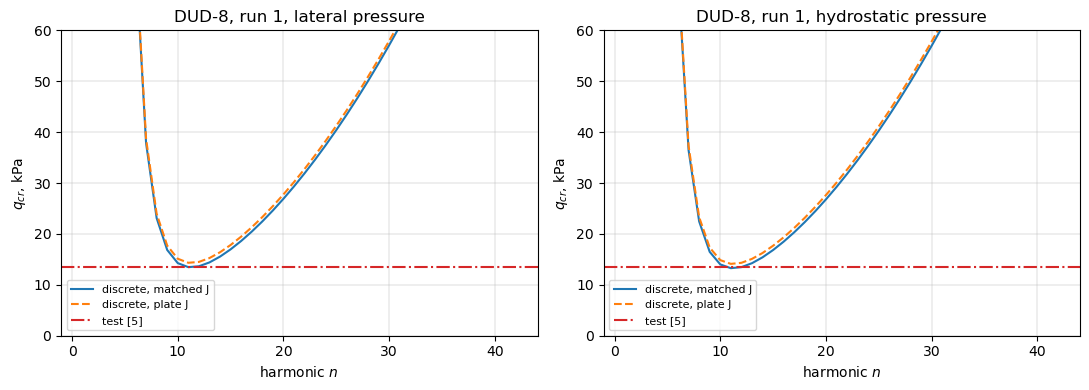

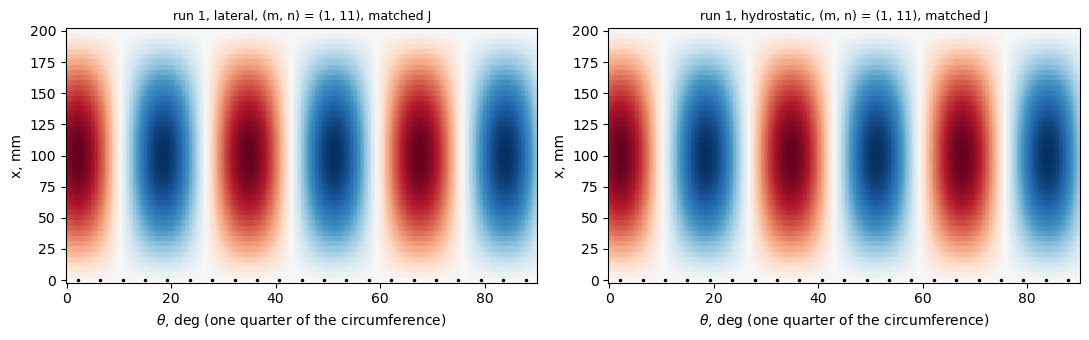

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, load in zip(axes, ('lateral', 'hydrostatic')):
    for J, style in (('matched', 'C0-'), ('plate', 'C1--')):
        out = resC[(mesh, J, 1, load)][1]
        nn = sorted(out)
        ax.plot(nn, [KPA*out[k][0] for k in nn], style, label='discrete, %s J' % J)
    ax.axhline(DUD8[1][1], color='C3', ls='-.', label='test [5]')
    ax.set_ylim(0, 60)
    ax.set_xlabel('harmonic $n$')
    ax.set_ylabel('$q_{cr}$, kPa')
    ax.set_title('DUD-8, run 1, %s pressure' % load)
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, load in zip(axes, ('lateral', 'hydrostatic')):
    model, out, n = resC[(mesh, 'matched', 1, load)]
    w = normalize_phase(model.skin_field(out[n][2], W))
    th, wf = model.full_circumference(w, n)
    sel = th <= 2*np.pi/4
    ax.pcolormesh(np.degrees(th[sel]), model.xlin, wf[:, sel]/np.abs(wf).max(),
                  cmap='RdBu_r', vmin=-1, vmax=1, shading='auto')
    pos = (np.arange(model.nstringers) + 0.5)*model.phi
    pos = pos[pos <= 2*np.pi/4]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_xlabel(r'$\theta$, deg (one quarter of the circumference)')
    ax.set_ylabel('x, mm')
    ax.set_title('run 1, %s, (m, n) = (%d, %d), matched J' % (load, out[n][1], n), fontsize=9)
plt.tight_layout()
plt.show()

**Live (follower) pressure.** The pressure of the tests is the pressure of
a fluid, which stays normal to the deformed skin and acts on its deformed
area; [2] gives the load stiffness of this live pressure (p. 117) besides
the external work of the dead one. The live variant adds to the geometric
stiffness of the unit pressure the load stiffness of a unit follower pressure
on the skin, `update_KCfollower` of `BFSCCylinderSanders` (first-order area
vector, `quadratic=0`, the pressure on the middle surface of the skin, as the
hoop force $q R$); the end load of the hydrostatic pressure acts on the rigid
end plates and stays a dead axial load:

$$\left(\boldsymbol{K} + \bar{N}_P \boldsymbol{K}_{G,x} + q
\left(\boldsymbol{K}_{G,q} + \boldsymbol{K}_F\right)\right) \boldsymbol{x}
= \boldsymbol{0}$$

The load stiffness $\boldsymbol{K}_F$ is unsymmetric in general, symmetric
when every edge of the loaded surface has $w = 0$ or a zero normal
displacement (Hibbitt 1979; Schweizerhof and Ramm 1984, Table 2): here the
ends have $w = 0$ and the sector edges are cyclic, so its skew part is a
check (printed below, for the sector and for the matrices of one harmonic).
With the complex basis of the harmonic $n$ the problem is solved as the real
problem of twice the size, $\begin{bmatrix} \Re & -\Im \\ \Im & \Re
\end{bmatrix}$ of both matrices (each real load multiplier appears twice),
with `structsolve.lb(..., symmetric=False)`: the shift search of
`scipy.sparse.linalg.eigs` along the positive real axis for the lowest
positive real load multiplier, with a parity check of the number of real
multipliers below it. This takes about five times as long per harmonic as
the Hermitian problem of the dead pressure, so the live pressure is solved
for the harmonics $n_d - 5 \ldots n_d + 5$ around the critical harmonic $n_d$
of the dead pressure: the live load stiffness lowers $q$ by about one
percent for every harmonic, whereas $q$ of the dead pressure is more than 10
% higher than the minimum five harmonics away (figure above). Finest mesh,
matched $J$; run 1 also on the mesh before (convergence).

In [16]:
from scipy.sparse import bmat
from structsolve import lb


def KF_skin(model):
    # load stiffness of a unit external follower pressure (p = -1) on the skin
    p, w = model.points, model.weights
    pq = -np.ones((len(p), len(p)))
    u0 = np.zeros(model.N)

    def skin(shell, k, r, c, v):
        shell.init_k_KCfollower = k
        model._sk.update_KCfollower(u0, shell, p, w, pq, r, c, v, 0)

    def stringer(plate, k, r, c, v):
        pass  # the pressure acts on the skin only
    return model._assemble(skin, model._sk.KCfollower_SPARSE_SIZE, stringer, 0)


def realify(A):
    return bmat([[A.real, -A.imag], [A.imag, A.real]]).tocsr()


def skew(A):
    A = A.tocsr()
    return np.sqrt(np.sum(np.abs((A - A.conj().T).data)**2))/np.sqrt(np.sum(np.abs(A.data)**2))


def live_matrices(model, n, kappa, P):
    if not hasattr(model, '_KGx'):
        buckling_pressure(model, 1, kappa, P)  # sets _KGx and _KGh
    if not hasattr(model, '_KF'):
        model._KF = KF_skin(model)
    Zn = model.Z(n, free_axial=True)
    K = Zn.conj().T @ model.KC0() @ Zn
    if P:
        K = K + P*(Zn.conj().T @ model._KGx @ Zn)
    KGq = Zn.conj().T @ (model._KGh + kappa*model.R/2*model._KGx + model._KF) @ Zn
    bu = ~model.constrained('SS')
    return K.tocsr()[bu][:, bu], KGq.tocsr()[bu][:, bu], Zn, bu


def buckling_pressure_live(model, n, kappa, P):
    K, KGq, Zn, bu = live_matrices(model, n, kappa, P)
    nb = K.shape[0]
    lam, Y = lb(realify(K), realify(KGq), silent=True, num_eigvalues=4, symmetric=False)
    ur = np.zeros(model.Nr, dtype=complex)
    ur[bu] = Y[:nb, 0] + 1j*Y[nb:, 0]
    return float(np.real(lam[0])), Zn @ ur


def scan_pressure_live(model, kappa, P, n_dead, half=5):
    # harmonics n_dead - half ... n_dead + half around the critical one of the dead pressure
    out = {}
    for n in range(max(1, n_dead - half), min(model.nstringers//2, n_dead + half) + 1):
        q, x = buckling_pressure_live(model, n, kappa, P)
        out[n] = (q, axial_nodes(model, x) + 1, x)
    n = min(out, key=lambda n: out[n][0])
    return out, n


t0 = time.time()
for run, load, kappa, P in LOADS:
    for msh in (MESHES_C[-2:] if run == 1 else MESHES_C[-1:]):
        model, out, n = resC[(msh, 'matched', run, load)]
        resC[(msh, 'live', run, load)] = (model,) + scan_pressure_live(model, kappa, P, n)
print('%.0f s' % (time.time() - t0))
model = resC[(mesh, 'live', 1, 'lateral')][0]
n1 = resC[(mesh, 'live', 1, 'lateral')][2]
print('skew part ||KF - KF^H||/||KF||: sector %.1e; harmonic n = %d, K_G,q + K_F: %.1e'
      % (skew(model._KF), n1, skew(live_matrices(model, n1, 0, 0.)[1])))
rows = []
for run, load, kappa, P in LOADS:
    P_kN, test, ss3 = DUD8[run][:3]
    md_, outd, nd = resC[(mesh, 'matched', run, load)]
    ml_, outl, nl = resC[(mesh, 'live', run, load)]
    qd, ql = outd[nd][0], outl[nl][0]
    row = [run, P_kN, load, '%.2f' % (KPA*qd), '%.2f (%d, %d)' % (KPA*ql, outl[nl][1], nl),
           '**%+.2f %%**' % pct(ql, qd), test, '%+.1f %%' % pct(KPA*ql, test), ss3, '%+.1f %%' % pct(KPA*ql, ss3)]
    if run in POORVEIS_C:
        row += ['%.2f' % (KPA*POORVEIS_C[run][2]), '%+.1f %%' % pct(ql, POORVEIS_C[run][2])]
    else:
        row += ['-', '-']
    rows.append(row)
table(['run', 'P, kN', 'pressure', 'dead q', 'live q (m, n)', 'live vs dead', 'test [5]', 'live vs test',
       'SS3 of [5]', 'live vs SS3 of [5]', 'discrete [2]', 'live vs discrete [2]'], rows)
rows = []
for load in ('lateral', 'hydrostatic'):
    q1, q2 = (resC[(msh, 'live', 1, load)][1][resC[(msh, 'live', 1, load)][2]][0] for msh in MESHES_C[-2:])
    rows.append([load, MESHES_C[-2], '%.3f' % (KPA*q1), MESHES_C[-1], '%.3f' % (KPA*q2), '%+.2f %%' % pct(q2, q1)])
table(['run 1, live', 'mesh', 'q, kPa', 'mesh', 'q, kPa', 'change'], rows)

2670 s
skew part ||KF - KF^H||/||KF||: sector 4.6e-01; harmonic n = 11, K_G,q + K_F: 5.2e-17


| run | P, kN | pressure | dead q | live q (m, n) | live vs dead | test [5] | live vs test | SS3 of [5] | live vs SS3 of [5] | discrete [2] | live vs discrete [2] |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.0 | lateral | 13.47 | 13.36 (1, 11) | **-0.79 %** | 13.55 | -1.4 % | 13.3 | +0.5 % | 14.80 | -9.7 % |
| 1 | 0.0 | hydrostatic | 13.27 | 13.17 (1, 11) | **-0.78 %** | 13.55 | -2.8 % | 13.3 | -1.0 % | 14.80 | -11.0 % |
| 2 | 4.0 | lateral | 12.15 | 12.05 (1, 11) | **-0.79 %** | 12.3 | -2.0 % | 12.0 | +0.4 % | - | - |
| 2 | 4.0 | hydrostatic | 11.97 | 11.88 (1, 11) | **-0.78 %** | 12.3 | -3.4 % | 12.0 | -1.0 % | - | - |
| 3 | 8.0 | lateral | 10.83 | 10.74 (1, 11) | **-0.79 %** | 11.1 | -3.2 % | 10.7 | +0.4 % | 12.70 | -15.4 % |
| 3 | 8.0 | hydrostatic | 10.67 | 10.58 (1, 11) | **-0.78 %** | 11.1 | -4.6 % | 10.7 | -1.1 % | 12.70 | -16.7 % |

| run 1, live | mesh | q, kPa | mesh | q, kPa | change |
|---|---|---|---|---|---|
| lateral | (37, 16, 5) | 13.372 | (49, 16, 5) | 13.364 | -0.06 % |
| hydrostatic | (37, 16, 5) | 13.176 | (49, 16, 5) | 13.168 | -0.06 % |

**Interaction curve of DUD-8.** Shen, Zhou and Chen [3] (Fig. 3(a), p. 57)
give the interaction curve of DUD-8 under combined hydrostatic pressure and
axial load from their boundary-layer postbuckling theory (simply supported
ends, perfect shell and an imperfection $W^*/t = 0.04$), with the tests of
[5], as $R_x = \lambda_p/\lambda_p^*$ against $R_y = \lambda_q/\lambda_q^*$, the
loads divided by their theoretical values under axial compression alone
and external pressure alone (notation, p. 44), which [3] does not print.
Digitized here (reading precision $\pm 0.01$): perfect shell $R_x = 1.00,
0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.23, 0.12, 0$ at $R_y = 0, 0.1,
\ldots, 1.0$; tests $(R_y, R_x) = (0.00, 0.93), (0.83, 0.21), (0.93, 0.10),
(1.01, 0.00)$. The discrete model adds $P = 16$ and 24 kN (dead pressure)
to the runs of [5]; the curves of equation (15) are those of the section
of [2]. Left: absolute values with the tests and the SS3 predictions of [5]
(Table 4); right: each curve divided by its own values under pressure alone
and axial load alone, as [3] does.

993 s


| P, kN | pressure | discrete q, kPa (m, n) | Eq. (15), same strip | gap | R_x = P/P_ax | R_y = q/q(P = 0) |
|---|---|---|---|---|---|---|
| 0.0 | lateral | 13.47 (1, 11) | 13.42 | +0.4 % | 0.000 | 1.000 |
| 4.0 | lateral | 12.15 (1, 11) | 12.12 | +0.2 % | 0.118 | 0.902 |
| 8.0 | lateral | 10.83 (1, 11) | 10.83 | +0.0 % | 0.236 | 0.804 |
| 16.0 | lateral | 7.85 (1, 10) | 7.88 | -0.4 % | 0.473 | 0.582 |
| 24.0 | lateral | 4.64 (1, 10) | 4.74 | -2.2 % | 0.709 | 0.344 |
| 0.0 | hydrostatic | 13.27 (1, 11) | 13.23 | +0.3 % | 0.000 | 1.000 |
| 4.0 | hydrostatic | 11.97 (1, 11) | 11.95 | +0.2 % | 0.118 | 0.902 |
| 8.0 | hydrostatic | 10.67 (1, 11) | 10.67 | -0.0 % | 0.236 | 0.804 |
| 16.0 | hydrostatic | 7.71 (1, 10) | 7.74 | -0.5 % | 0.473 | 0.581 |
| 24.0 | hydrostatic | 4.55 (1, 10) | 4.66 | -2.2 % | 0.709 | 0.343 |

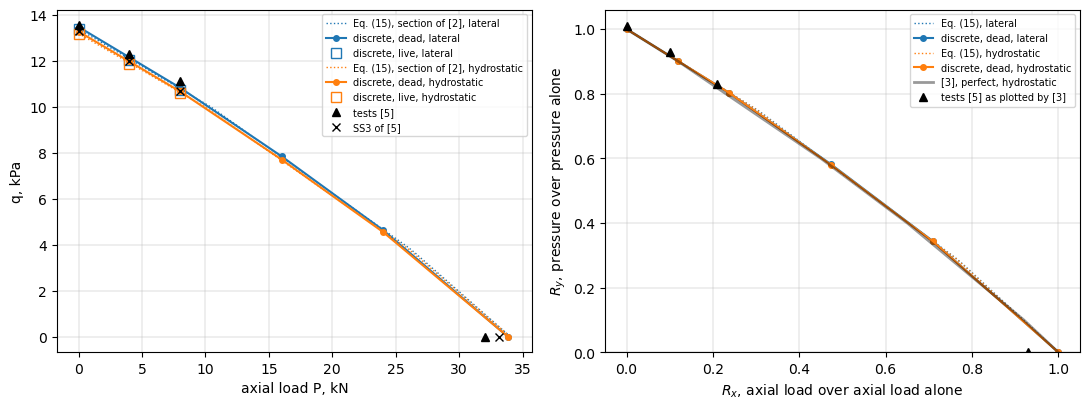

In [17]:
# Shen, Zhou and Chen (1993), Fig. 3(a), p. 57, digitized (+-0.01): perfect shell and tests of [5]
SHEN_F3A_RY = np.linspace(0., 1., 11)
SHEN_F3A_RX = np.array([1.00, 0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.23, 0.12, 0.])
SHEN_F3A_TESTS = np.array([(0.00, 0.93), (0.83, 0.21), (0.93, 0.10), (1.01, 0.00)])
P_EXTRA = (16., 24.)  # kN
t0 = time.time()
model = resC[(mesh, 'matched', 1, 'lateral')][0]
for P_kN in P_EXTRA:
    for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
        resC[(mesh, 'matched', 'P%g' % P_kN, load)] = (model,) + scan_pressure(model, kappa, Nbar(P_kN))
print('%.0f s' % (time.time() - t0))
Pax = kN*axC['matched'][1][axC['matched'][2]][0]  # discrete, axial compression alone, kN
rows = []
curves = {}
for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
    keys = sorted([(run, DUD8[run][0]) for run in DUD8] + [('P%g' % P_kN, P_kN) for P_kN in P_EXTRA],
                  key=lambda k: k[1])
    out0, n0 = resC[(mesh, 'matched', 1, load)][1:]
    q0 = out0[n0][0]
    pts = []
    for key, P_kN in keys:
        out, n = resC[(mesh, 'matched', key, load)][1:]
        q, m = out[n][:2]
        pts.append((P_kN, KPA*q))
        sm = smeared_q(dc, *Psec, dc['J'], kappa, Nbar(P_kN))
        rows.append([P_kN, load, '%.2f (%d, %d)' % (KPA*q, m, n), '%.2f' % (KPA*sm[0]),
                     '%+.1f %%' % pct(q, sm[0]), '%.3f' % (P_kN/Pax), '%.3f' % (q/q0)])
    curves[load] = np.array(pts + [(Pax, 0.)])
table(['P, kN', 'pressure', 'discrete q, kPa (m, n)', 'Eq. (15), same strip', 'gap', 'R_x = P/P_ax',
       'R_y = q/q(P = 0)'], rows)

Ps = np.linspace(0., kN*sma['W'][0], 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for load, kappa, c in (('lateral', 0, 'C0'), ('hydrostatic', 1, 'C1')):
    qs = np.array([smeared_q(dc, *Wsec, dc['J'], kappa, Nbar(P))[0] for P in Ps])
    axes[0].plot(Ps, KPA*qs, c + ':', lw=1, label='Eq. (15), section of [2], %s' % load)
    axes[0].plot(curves[load][:, 0], curves[load][:, 1], c + 'o-', ms=4, label='discrete, dead, %s' % load)
    ql = [resC[(mesh, 'live', r, load)][1][resC[(mesh, 'live', r, load)][2]][0] for r in DUD8]
    axes[0].plot([DUD8[r][0] for r in DUD8], KPA*np.array(ql), c + 's', mfc='none', ms=7,
                 label='discrete, live, %s' % load)
    axes[1].plot(Ps/Ps[-1], qs/qs[0], c + ':', lw=1, label='Eq. (15), %s' % load)
    axes[1].plot(curves[load][:, 0]/Pax, curves[load][:, 1]/curves[load][0, 1], c + 'o-', ms=4,
                 label='discrete, dead, %s' % load)
axes[0].plot([DUD8[r][0] for r in DUD8] + [DUD8_AXIAL[0]], [DUD8[r][1] for r in DUD8] + [0.], 'k^',
             label='tests [5]')
axes[0].plot([DUD8[r][0] for r in DUD8] + [DUD8_AXIAL[1]], [DUD8[r][2] for r in DUD8] + [0.], 'kx',
             label='SS3 of [5]')
axes[0].set_xlabel('axial load P, kN')
axes[0].set_ylabel('q, kPa')
axes[1].plot(SHEN_F3A_RX, SHEN_F3A_RY, 'k-', lw=2, alpha=0.4, label='[3], perfect, hydrostatic')
axes[1].plot(SHEN_F3A_TESTS[:, 1], SHEN_F3A_TESTS[:, 0], 'k^', label='tests [5] as plotted by [3]')
axes[1].set_xlabel('$R_x$, axial load over axial load alone')
axes[1].set_ylabel('$R_y$, pressure over pressure alone')
axes[1].set_ylim(bottom=0)
for ax in axes:
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## Shell DUD-10 of [5]: combined loading in the reversed sequence

DUD-10 is the "twin" of DUD-8 (case C), machined from the same blank ([5],
p. 2). [5] buckled it four times (Table 5, p. 10), the first combined run in
the reversed sequence: the pressure held at $p = 11.1$ kPa and the axial load
increased up to buckling (run 2), then the axial load held at $P = 3.8$ kN
and the pressure increased (run 3). Shen, Zhou and Chen [3] plot its
interaction curve as Fig. 3(b) (p. 57). Neither [2] nor [3] gives its section;
the values below are those of [5].

**Geometry and stringers.** Table 1 of [5] (p. 2), DUD-10: $h = 0.252$ mm,
$L = 200$ mm, $R/h = 476$, $L/R = 1.665$, stringer height $d_1 = 1.755$ mm
and width $c_1 = 0.85$ mm, $b_1/h = 35.65$, $A_{11}/(b_1 h) = 0.659$,
$I_{11}/(b_1 h^3) = 2.66$, $e_1/h = -3.98$; footnote: $R = 120.12$ mm,
$b_1 = 8.985$ mm for DUD-8 to DUD-11, 84 integral external stringers,
7075-T6, $E = 7.5 \times 10^4$ MPa, $\nu = 0.3$. For DUD-10 these agree:
$L/(L/R) = 120.12$ mm, $84 \times 35.65 h/(2\pi) = 120.11$ mm, while
$476 h = 119.95$ mm is $R/h$ rounded to an integer; $R = 120.12$ mm is used,
119.95 mm as a sensitivity of equation (15). The stringer is the rectangle
$c_1 \times d_1$: $c_1 d_1$, $c_1 d_1^3/12$ and $(h + d_1)/2$ reproduce the
area, the moment of inertia and the eccentricity of Table 1 (checked below);
the model takes $h_s = \sqrt{12 I_{11}/A_{11}}$ and $t_s = A_{11}/h_s$ from
the non-dimensional values, as for the other shells. The torsion constant is
not printed for DUD-10; it is taken as the Saint-Venant constant of the
rectangle $c_1 \times d_1$ (the $I_{t1}$ of the shells of [1] is that of the
rectangle, and for DUD-8 the rectangle is within 1 % of $G_1 J_1/(bD)$ of
[2]; printed below), with the plate $J$ and, in equation (15), $J = 0$ as
the sensitivity.

**Tests and predictions of [5]** (Table 5, p. 10; ends between SS-3 and SS-4
by the vibration correlation technique, p. 9; modes $(n/m)$):

| run | load | test | SS3 | SS4 | equivalent springs |
|---|---|---|---|---|---|
| 1 | external pressure, kPa | 12.6 (10/1) | 13.6 (11/1) | 17.1 (13/1) | 14.5 (11/1) |
| 2 | axial load, kN, at $p = 11.1$ kPa | 3.80 (9/1) | 7.99 (11/1) | 23.42 (12/1) | 13.80 (11/1) |
| 3 | pressure, kPa, at $P = 3.8$ kN | 11.3 (9/1) | 12.4 (11/1) | 16.3 (12/1) | 13.2 (11/1) |
| 4 | axial compression, kN | 32. (7/1) | 33.66 (9/1) | 54.90 (12/1) | 41.20 (10/1) |

The ratios $\varrho_{SS3} = 0.93$, 0.48, 0.91, 0.95 are test over SS3. [5]
attributes the low axial load of run 2 to the growth of the initial
imperfections under the pressure held first (p. 8): the pressure of run 3
(11.3 kPa at 3.8 kN) is close to the 11.1 kPa at which run 2 buckled at 3.8
kN.

**Model.** Units, pressure types (lateral and hydrostatic, dead and live),
equation (15) and the discrete model (sector of one stringer pitch, every
harmonic $n \le 42$) are those of case C. Runs 1 and 3 give
the pressure at a fixed axial load. Run 2 holds the pressure: equation (15)
and the discrete model give the axial load at which the critical pressure
equals 11.1 kPa, found as the root of $q(P) - 11.1$ kPa ($q$ decreases
monotonically with $P$): Brent's method on equation (15), the secant method
on the discrete model (bisection when a step leaves the bracket of the root), to a relative tolerance of $10^{-4}$ on $q$ (each
iteration scans the harmonics $n_3 - 5 \ldots n_3 + 5$ around the critical
harmonic $n_3$ of run 3, as the live pressure of case C does).

In [18]:
from scipy.optimize import brentq

# Abramovich, Weller and Singer (1988) [5], Table 1 (p. 2), DUD-10: h, L (mm), R/h, L/R, d1, c1 (mm),
# b1/h, A11/(b1 h), I11/(b1 h^3), e1/h; footnote: R = 120.12 mm, 84 external stringers
hE, LE, RhE, LRE, d1, c1, b1hE, AbE, IbE, ehE = (0.252, 200., 476, 1.665, 1.755, 0.85, 35.65, 0.659, 2.66, -3.98)
RE, nsE = 120.12, 84
# Table 5 of [5] (p. 10): test, SS3, SS4, equivalent springs; runs 1 and 3 in kPa, runs 2 and 4 in kN
DUD10 = {1: (12.6, 13.6, 17.1, 14.5), 2: (3.80, 7.99, 23.42, 13.80), 3: (11.3, 12.4, 16.3, 13.2),
         4: (32., 33.66, 54.90, 41.20)}
P_RUN3, Q_RUN2 = 3.8, 11.1  # kN, kPa: the load held constant in runs 3 and 2
bE = 2*np.pi*RE/nsE
de = dict(h=hE, R=RE, L=LE, ns=nsE, b=bE, A=AbE*bE*hE, I=IbE*bE*hE**3, e=-ehE*hE, J=rect_J(c1, d1))
de['hs'] = np.sqrt(12*de['I']/de['A'])
de['ts'] = de['A']/de['hs']
de['Hs'] = de['hs'] + hE/2
de['Jplate'] = de['Hs']*de['ts']**3/3
shells['DUD-10'] = de
deR = dict(de, R=RhE*hE, b=2*np.pi*RhE*hE/nsE)  # sensitivity: R = (R/h) h
kNe = 2*np.pi*RE*10/1e3  # kN per unit axial force per unit circumference
print('R: L/(L/R) = %.2f mm, 84 b1/(2 pi) = %.2f mm, (R/h) h = %.2f mm; b1 = 2 pi R/84 = %.3f mm (b1/h h = %.3f mm)'
      % (LE/LRE, nsE*b1hE*hE/(2*np.pi), RhE*hE, bE, b1hE*hE))
print('rectangle c1 x d1 against Table 1: area %.4f (%.4f) mm^2, I11 %.4f (%.4f) mm^4, e1 %.4f (%.4f) mm'
      % (c1*d1, de['A'], c1*d1**3/12, de['I'], (hE + d1)/2, de['e']))
print('model: h_s = %.3f mm (d1 = %.3f), t_s = %.3f mm (c1 = %.2f), J = %.4f mm^4, G J/(b D) = %.3f, '
      'J/J_plate = %.3f, theta = %.3f'
      % (de['hs'], d1, de['ts'], c1, de['J'], G*de['J']/(bE*E*D_E*hE**3), de['J']/de['Jplate'],
         k4*bE/(2*np.pi*np.sqrt(RE*hE))))
print('DUD-8 (case C): J of the rectangle t_s x h_s %.4f mm^4 against I_t1 = %.4f mm^4 of [2] (%+.1f %%)'
      % (rect_J(dc['ts'], dc['hs']), dc['J'], pct(rect_J(dc['ts'], dc['hs']), dc['J'])))

WsE = (de['A'], de['e'], de['I'] + de['A']*de['e']**2)
PsE = (de['ts']*de['Hs'], de['Hs']/2, de['ts']*de['Hs']**3/3)
SECS_E = {'W': (de, WsE, de['J']), 'W_J0': (de, WsE, 0.), 'W_R': (deR, WsE, de['J']),
          'matched': (de, PsE, de['J']), 'plate': (de, PsE, de['Jplate'])}


def smeared_E(key, run, kappa):
    # equation (15) for run 1 to 4: pressure (kPa) of runs 1 and 3, axial load (kN) of runs 2 and 4, (m, n)
    d_, sec, J = SECS_E[key]
    kN_ = 2*np.pi*d_['R']*10/1e3
    if run == 4:
        N, mn = smeared(d_, *sec, J)
        return kN_*N, mn
    if run in (1, 3):
        q, mn = smeared_q(d_, *sec, J, kappa, (P_RUN3 if run == 3 else 0.)/kN_)
        return KPA*q, mn
    f = lambda N: smeared_q(d_, *sec, J, kappa, N)[0] - Q_RUN2/KPA
    N = brentq(f, 0., smeared(d_, *sec, J)[0], xtol=1e-12)
    return kN_*N, smeared_q(d_, *sec, J, kappa, N)[1]


smE = {}
rows = []
for run in (1, 2, 3, 4):
    for load, kappa in ((('lateral', 0), ('hydrostatic', 1)) if run < 4 else (('axial', 0),)):
        smE[(run, load)] = {k: smeared_E(k, run, kappa) for k in SECS_E}
        s = smE[(run, load)]
        test, ss3 = DUD10[run][:2]
        rows.append([run, load, '%.2f %s' % s['W'], '%.2f' % s['W_J0'][0], '%.2f' % s['W_R'][0],
                     '%.2f %s' % s['matched'], '%.2f' % s['plate'][0], ss3, '%+.1f %%' % pct(s['W'][0], ss3),
                     test, '%+.1f %%' % pct(s['W'][0], test)])
table(['run', 'load', 'Eq. (15), section of [5] (m, n)', 'same, J = 0', 'same, R = 119.95 mm',
       'Eq. (15), strip, matched J', 'Eq. (15), strip, plate J', 'SS3 of [5]', 'section of [5] vs SS3 of [5]',
       'test [5]', 'section of [5] vs test'], rows)
print('runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN')

R: L/(L/R) = 120.12 mm, 84 b1/(2 pi) = 120.10 mm, (R/h) h = 119.95 mm; b1 = 2 pi R/84 = 8.985 mm (b1/h h = 8.984 mm)
rectangle c1 x d1 against Table 1: area 1.4917 (1.4921) mm^2, I11 0.3829 (0.3825) mm^4, e1 1.0035 (1.0030) mm
model: h_s = 1.754 mm (d1 = 1.755), t_s = 0.851 mm (c1 = 0.85), J = 0.2504 mm^4, G J/(b D) = 7.315, J/J_plate = 0.649, theta = 0.472
DUD-8 (case C): J of the rectangle t_s x h_s 0.2498 mm^4 against I_t1 = 0.2482 mm^4 of [2] (+0.7 %)


| run | load | Eq. (15), section of [5] (m, n) | same, J = 0 | same, R = 119.95 mm | Eq. (15), strip, matched J | Eq. (15), strip, plate J | SS3 of [5] | section of [5] vs SS3 of [5] | test [5] | section of [5] vs test |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | lateral | 13.72 (1, 11) | 12.07 | 13.75 | 13.76 (1, 11) | 14.65 | 13.6 | +0.9 % | 12.6 | +8.9 % |
| 1 | hydrostatic | 13.52 (1, 11) | 11.89 | 13.55 | 13.56 (1, 11) | 14.44 | 13.6 | -0.6 % | 12.6 | +7.3 % |
| 2 | lateral | 8.07 (1, 11) | 2.98 | 8.16 | 8.20 (1, 11) | 10.82 | 7.99 | +0.9 % | 3.8 | +112.3 % |
| 2 | hydrostatic | 7.56 (1, 11) | 2.47 | 7.66 | 7.70 (1, 11) | 10.32 | 7.99 | -5.4 % | 3.8 | +99.0 % |
| 3 | lateral | 12.48 (1, 11) | 10.83 | 12.51 | 12.53 (1, 11) | 13.42 | 12.4 | +0.7 % | 11.3 | +10.5 % |
| 3 | hydrostatic | 12.30 (1, 11) | 10.68 | 12.33 | 12.35 (1, 11) | 13.23 | 12.4 | -0.8 % | 11.3 | +8.9 % |
| 4 | axial | 34.58 (1, 9) | 31.17 | 34.59 | 34.84 (1, 9) | 36.68 | 33.66 | +2.7 % | 32.0 | +8.1 % |

runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN


**Convergence** (matched $J$, runs 1 and 3, dead pressure, every harmonic;
the meshes of case C).

In [19]:
t0 = time.time()
resE = {}
LOADS_E = [(run, load, kappa, P_RUN3/kNe if run == 3 else 0.) for run in (1, 3)
           for load, kappa in (('lateral', 0), ('hydrostatic', 1))]
for msh in MESHES_C:
    model = build(de, msh)
    for run, load, kappa, P in LOADS_E:
        resE[(msh, 'matched', run, load)] = (model,) + scan_pressure(model, kappa, P)
rows = []
for run, load, kappa, P in LOADS_E:
    prev = None
    for msh in MESHES_C:
        model, out, n = resE[(msh, 'matched', run, load)]
        q, m, _ = out[n]
        rows.append([run, load, msh, model.Nr, '%.3f' % (KPA*q), '(%d, %d)' % (m, n),
                     '' if prev is None else '%+.2f %%' % pct(q, prev)])
        prev = q
table(['run', 'pressure', 'mesh', 'dofs per harmonic', 'q_cr, kPa', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| run | pressure | mesh | dofs per harmonic | q_cr, kPa | (m, n) | change |
|---|---|---|---|---|---|---|
| 1 | lateral | (17, 8, 3) | 1904 | 13.897 | (1, 11) |  |
| 1 | lateral | (25, 12, 4) | 4050 | 13.843 | (1, 11) | -0.39 % |
| 1 | lateral | (37, 16, 5) | 7844 | 13.819 | (1, 11) | -0.17 % |
| 1 | lateral | (49, 16, 5) | 10388 | 13.810 | (1, 11) | -0.06 % |
| 1 | hydrostatic | (17, 8, 3) | 1904 | 13.692 | (1, 11) |  |
| 1 | hydrostatic | (25, 12, 4) | 4050 | 13.639 | (1, 11) | -0.39 % |
| 1 | hydrostatic | (37, 16, 5) | 7844 | 13.615 | (1, 11) | -0.17 % |
| 1 | hydrostatic | (49, 16, 5) | 10388 | 13.607 | (1, 11) | -0.06 % |
| 3 | lateral | (17, 8, 3) | 1904 | 12.642 | (1, 11) |  |
| 3 | lateral | (25, 12, 4) | 4050 | 12.587 | (1, 11) | -0.43 % |
| 3 | lateral | (37, 16, 5) | 7844 | 12.563 | (1, 11) | -0.19 % |
| 3 | lateral | (49, 16, 5) | 10388 | 12.555 | (1, 11) | -0.07 % |
| 3 | hydrostatic | (17, 8, 3) | 1904 | 12.455 | (1, 11) |  |
| 3 | hydrostatic | (25, 12, 4) | 4050 | 12.402 | (1, 11) | -0.43 % |
| 3 | hydrostatic | (37, 16, 5) | 7844 | 12.378 | (1, 11) | -0.19 % |
| 3 | hydrostatic | (49, 16, 5) | 10388 | 12.370 | (1, 11) | -0.07 % |

1636 s


**Results** (finest level; dead pressure; plate $J$ for runs 1, 3 and 4).
Run 2: the axial load at which the critical pressure is 11.1 kPa (secant
iterations from the results at $P = 3.8$ and 8 kN; the number of iterations
is printed); run 4 with `scan` of the axial cases. The loads at $P = 8$, 16 and
24 kN complete the interaction curve. "Gap": discrete model against equation
(15) for the same strip and twisting stiffness.

In [20]:
t0 = time.time()
modelE = resE[(mesh, 'matched', 1, 'lateral')][0]
modelEp = build(de, mesh, 'plate')
for run, load, kappa, P in LOADS_E:
    resE[(mesh, 'plate', run, load)] = (modelEp,) + scan_pressure(modelEp, kappa, P)
for P_kN in (8., 16., 24.):
    for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
        resE[(mesh, 'matched', 'P%g' % P_kN, load)] = (modelE,) + scan_pressure(modelE, kappa, P_kN/kNe)
axE = {J: scan(de, mesh, J) for J in ('matched', 'plate')}


def scan_pressure_near(model, kappa, P, n0, half=5):
    # dead pressure, harmonics n0 - half ... n0 + half
    out = {}
    for n in range(max(1, n0 - half), min(model.nstringers//2, n0 + half) + 1):
        q, X = buckling_pressure(model, n, kappa, P)
        out[n] = (q[0], axial_nodes(model, X[:, 0]) + 1, X[:, 0])
    n = min(out, key=lambda n: out[n][0])
    return out, n


def qof(out_n):
    out, n = out_n
    return out[n][0]


def secant_P(q_target, P0, q0, P1, q1, run_at, Pmax, tol=1e-4, maxit=20):
    # axial force (units of the model) at which the critical pressure equals q_target: secant steps
    # kept inside the bracket [lo, hi], q(lo) > q_target > q(hi), bisection when a step leaves it;
    # Pmax, the axial load alone (q = 0), is the first upper bound
    lo, hi = 0., Pmax
    for P, q in ((P0, q0), (P1, q1)):
        lo, hi = (max(lo, P), hi) if q > q_target else (lo, min(hi, P))
    for it in range(1, maxit + 1):
        P = P1 + (q_target - q1)*(P1 - P0)/(q1 - q0)
        if not lo < P < hi:
            P = (lo + hi)/2
        res = run_at(P)
        if abs(qof(res)/q_target - 1) < tol:
            return P, res, it
        lo, hi = (max(lo, P), hi) if qof(res) > q_target else (lo, min(hi, P))
        P0, q0, P1, q1 = P1, q1, P, qof(res)
    raise RuntimeError('secant: no convergence')


for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
    n3 = resE[(mesh, 'matched', 3, load)][2]
    resE[(mesh, 'matched', 2, load)] = secant_P(
        Q_RUN2/KPA, P_RUN3/kNe, qof(resE[(mesh, 'matched', 3, load)][1:]), 8./kNe,
        qof(resE[(mesh, 'matched', 'P8', load)][1:]),
        lambda P: scan_pressure_near(modelE, kappa, P, n3), qof(axE['matched'][1:]))
print('%.0f s' % (time.time() - t0))
rows = []
for run in (1, 2, 3, 4):
    test, ss3, ss4, sp = DUD10[run]
    for load in (('lateral', 'hydrostatic') if run < 4 else ('axial',)):
        for J in (('matched', 'plate') if run != 2 else ('matched',)):
            sm = smE[(run, load)][J]
            if run in (1, 3):
                model, out, n = resE[(mesh, J, run, load)]
                val, m, extra = KPA*out[n][0], out[n][1], ''
            elif run == 2:
                P, (out, n), it = resE[(mesh, J, 2, load)]
                val, m = kNe*P, out[n][1]
                edge = ' (window edge)' if n in (min(out), max(out)) else ''
                extra = ', %d secant iterations, q = %.4f kPa%s' % (it, KPA*out[n][0], edge)
            else:
                model, out, n = axE[J]
                val, m, extra = kNe*out[n][0], out[n][1], ''
            rows.append([run, load, J, '%.2f (%d, %d)%s' % (val, m, n, extra), '%.2f' % sm[0],
                         '**%+.1f %%**' % pct(val, sm[0]), test, '%+.1f %%' % pct(val, test), ss3,
                         '%+.1f %%' % pct(val, ss3), ss4, sp])
table(['run', 'load', 'J', 'discrete (m, n)', 'Eq. (15), same strip', 'gap', 'test [5]', 'vs test',
       'SS3 of [5]', 'vs SS3 of [5]', 'SS4 of [5]', 'springs of [5]'], rows)
print('runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN')

2184 s


| run | load | J | discrete (m, n) | Eq. (15), same strip | gap | test [5] | vs test | SS3 of [5] | vs SS3 of [5] | SS4 of [5] | springs of [5] |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | lateral | matched | 13.81 (1, 11) | 13.76 | **+0.4 %** | 12.6 | +9.6 % | 13.6 | +1.5 % | 17.1 | 14.5 |
| 1 | lateral | plate | 14.68 (1, 11) | 14.65 | **+0.1 %** | 12.6 | +16.5 % | 13.6 | +7.9 % | 17.1 | 14.5 |
| 1 | hydrostatic | matched | 13.61 (1, 11) | 13.56 | **+0.3 %** | 12.6 | +8.0 % | 13.6 | +0.0 % | 17.1 | 14.5 |
| 1 | hydrostatic | plate | 14.46 (1, 11) | 14.44 | **+0.1 %** | 12.6 | +14.8 % | 13.6 | +6.3 % | 17.1 | 14.5 |
| 2 | lateral | matched | 8.20 (1, 11), 1 secant iterations, q = 11.1000 kPa | 8.20 | **+0.0 %** | 3.8 | +115.9 % | 7.99 | +2.7 % | 23.42 | 13.8 |
| 2 | hydrostatic | matched | 7.70 (1, 11), 1 secant iterations, q = 11.1000 kPa | 7.70 | **+0.0 %** | 3.8 | +102.6 % | 7.99 | -3.6 % | 23.42 | 13.8 |
| 3 | lateral | matched | 12.55 (1, 11) | 12.53 | **+0.2 %** | 11.3 | +11.1 % | 12.4 | +1.2 % | 16.3 | 13.2 |
| 3 | lateral | plate | 13.42 (1, 11) | 13.42 | **-0.0 %** | 11.3 | +18.8 % | 12.4 | +8.2 % | 16.3 | 13.2 |
| 3 | hydrostatic | matched | 12.37 (1, 11) | 12.35 | **+0.2 %** | 11.3 | +9.5 % | 12.4 | -0.2 % | 16.3 | 13.2 |
| 3 | hydrostatic | plate | 13.22 (1, 11) | 13.23 | **-0.0 %** | 11.3 | +17.0 % | 12.4 | +6.6 % | 16.3 | 13.2 |
| 4 | axial | matched | 34.37 (1, 9) | 34.84 | **-1.3 %** | 32.0 | +7.4 % | 33.66 | +2.1 % | 54.9 | 41.2 |
| 4 | axial | plate | 36.10 (1, 9) | 36.68 | **-1.6 %** | 32.0 | +12.8 % | 33.66 | +7.2 % | 54.9 | 41.2 |

runs 1 and 3: pressure, kPa; runs 2 and 4: axial load, kN


**Live (follower) pressure**, as for case C (the harmonics $n_d - 5 \ldots
n_d + 5$ around the critical harmonic $n_d$ of the dead pressure): runs 1 and
3, and run 2 (the secant iterations repeated with the live pressure, from the
live results at $P = 0$ and 3.8 kN); finest mesh, matched $J$, run 1 also on
the mesh before (convergence).

In [21]:
t0 = time.time()
for run, load, kappa, P in LOADS_E:
    for msh in (MESHES_C[-2:] if run == 1 else MESHES_C[-1:]):
        model, out, n = resE[(msh, 'matched', run, load)]
        resE[(msh, 'live', run, load)] = (model,) + scan_pressure_live(model, kappa, P, n)
for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
    n2 = resE[(mesh, 'matched', 2, load)][1][1]
    resE[(mesh, 'live', 2, load)] = secant_P(
        Q_RUN2/KPA, 0., qof(resE[(mesh, 'live', 1, load)][1:]), P_RUN3/kNe,
        qof(resE[(mesh, 'live', 3, load)][1:]), lambda P: scan_pressure_live(modelE, kappa, P, n2), qof(axE['matched'][1:]))
print('%.0f s' % (time.time() - t0))
rows = []
for run in (1, 2, 3):
    test, ss3 = DUD10[run][:2]
    for load in ('lateral', 'hydrostatic'):
        if run == 2:
            vd, vl = kNe*resE[(mesh, 'matched', 2, load)][0], kNe*resE[(mesh, 'live', 2, load)][0]
            out, n = resE[(mesh, 'live', 2, load)][1]
        else:
            vd = KPA*qof(resE[(mesh, 'matched', run, load)][1:])
            out, n = resE[(mesh, 'live', run, load)][1:]
            vl = KPA*out[n][0]
        rows.append([run, load, '%.2f' % vd, '%.2f (%d, %d)' % (vl, out[n][1], n), '**%+.2f %%**' % pct(vl, vd),
                     test, '%+.1f %%' % pct(vl, test), ss3, '%+.1f %%' % pct(vl, ss3)])
table(['run', 'pressure', 'dead', 'live (m, n)', 'live vs dead', 'test [5]', 'live vs test', 'SS3 of [5]',
       'live vs SS3 of [5]'], rows)
rows = []
for load in ('lateral', 'hydrostatic'):
    q1, q2 = (qof(resE[(msh, 'live', 1, load)][1:]) for msh in MESHES_C[-2:])
    rows.append([load, MESHES_C[-2], '%.3f' % (KPA*q1), MESHES_C[-1], '%.3f' % (KPA*q2), '%+.2f %%' % pct(q2, q1)])
table(['run 1, live', 'mesh', 'q, kPa', 'mesh', 'q, kPa', 'change'], rows)
print('runs 1 and 3: pressure, kPa; run 2: axial load, kN')

3172 s


| run | pressure | dead | live (m, n) | live vs dead | test [5] | live vs test | SS3 of [5] | live vs SS3 of [5] |
|---|---|---|---|---|---|---|---|---|
| 1 | lateral | 13.81 | 13.70 (1, 11) | **-0.79 %** | 12.6 | +8.7 % | 13.6 | +0.7 % |
| 1 | hydrostatic | 13.61 | 13.50 (1, 11) | **-0.78 %** | 12.6 | +7.1 % | 13.6 | -0.7 % |
| 2 | lateral | 8.20 | 7.93 (1, 11) | **-3.28 %** | 3.8 | +108.8 % | 7.99 | -0.7 % |
| 2 | hydrostatic | 7.70 | 7.43 (1, 11) | **-3.49 %** | 3.8 | +95.6 % | 7.99 | -7.0 % |
| 3 | lateral | 12.55 | 12.46 (1, 11) | **-0.79 %** | 11.3 | +10.2 % | 12.4 | +0.4 % |
| 3 | hydrostatic | 12.37 | 12.27 (1, 11) | **-0.78 %** | 11.3 | +8.6 % | 12.4 | -1.0 % |

| run 1, live | mesh | q, kPa | mesh | q, kPa | change |
|---|---|---|---|---|---|
| lateral | (37, 16, 5) | 13.709 | (49, 16, 5) | 13.701 | -0.06 % |
| hydrostatic | (37, 16, 5) | 13.508 | (49, 16, 5) | 13.500 | -0.06 % |

runs 1 and 3: pressure, kPa; run 2: axial load, kN


**Interaction curve of DUD-10.** Fig. 3(b) of [3] (p. 57; $R/t = 477$, $Z =
1261$): the perfect shell and $W^*/t = 0.05$ under combined hydrostatic
pressure and axial load, with the tests of [5], normalized as in Fig. 3(a).
Digitized here from the scanned figure, calibrated on the end points of the
perfect-shell curve ($R_x = 1$ at $R_y = 0$ and $R_x = 0$ at $R_y = 1$, by the
normalization); the ticks at 0.5 of both axes give values up to 0.02 higher,
so the reading precision is $\pm 0.02$. Perfect shell: $R_x = 1.00, 0.92,
0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.22, 0.11, 0$ at $R_y = 0, 0.1, \ldots,
1.0$ (the same as Fig. 3(a) within the reading precision); tests $(R_y, R_x) =
(0.00, 0.92), (0.81, 0.11), (0.83, 0.11), (0.93, 0.00)$, the two middle ones
drawn as a pair (runs 2 and 3, $P = 3.8$ kN at 11.1 and 11.3 kPa). The tests
are shown as read. Left: absolute values with the tests and the SS3
predictions of [5] (Table 5); right: each curve divided by its own values
under pressure alone and axial load alone.

| P, kN | pressure | discrete q, kPa (m, n) | Eq. (15), same strip | gap | R_x = P/P_ax | R_y = q/q(P = 0) |
|---|---|---|---|---|---|---|
| 0.0 | lateral | 13.81 (1, 11) | 13.76 | +0.4 % | 0.000 | 1.000 |
| 3.8 | lateral | 12.55 (1, 11) | 12.53 | +0.2 % | 0.111 | 0.909 |
| 8.0 | lateral | 11.17 (1, 11) | 11.17 | +0.0 % | 0.233 | 0.809 |
| 16.0 | lateral | 8.14 (1, 10) | 8.17 | -0.4 % | 0.466 | 0.589 |
| 24.0 | lateral | 4.93 (1, 10) | 5.03 | -2.0 % | 0.698 | 0.357 |
| 8.20 (run 2) | lateral | 11.10 |  |  | 0.239 | 0.804 |
| 0.0 | hydrostatic | 13.61 (1, 11) | 13.56 | +0.3 % | 0.000 | 1.000 |
| 3.8 | hydrostatic | 12.37 (1, 11) | 12.35 | +0.2 % | 0.111 | 0.909 |
| 8.0 | hydrostatic | 11.00 (1, 11) | 11.00 | -0.0 % | 0.233 | 0.809 |
| 16.0 | hydrostatic | 7.99 (1, 10) | 8.03 | -0.4 % | 0.466 | 0.588 |
| 24.0 | hydrostatic | 4.84 (1, 10) | 4.94 | -2.0 % | 0.698 | 0.356 |
| 7.70 (run 2) | hydrostatic | 11.10 |  |  | 0.224 | 0.816 |

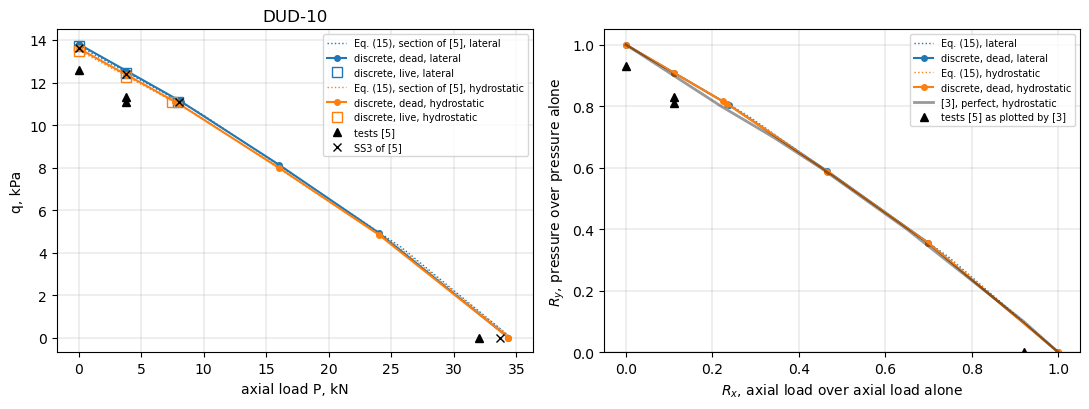

lateral, discrete R_x - Fig. 3(b) at R_y = 0, 0.1, ..., 1: +0.000 -0.004 +0.001 +0.007 +0.005 +0.005 +0.004 +0.009 +0.023 +0.012 +0.000
hydrostatic, discrete R_x - Fig. 3(b) at R_y = 0, 0.1, ..., 1: +0.000 -0.005 +0.000 +0.006 +0.004 +0.004 +0.002 +0.007 +0.022 +0.012 +0.000


In [22]:
# Shen, Zhou and Chen (1993), Fig. 3(b), p. 57, digitized (+-0.02): perfect shell and tests of [5]
SHEN_F3B_RY = np.linspace(0., 1., 11)
SHEN_F3B_RX = np.array([1.00, 0.92, 0.83, 0.74, 0.65, 0.55, 0.45, 0.34, 0.22, 0.11, 0.])
SHEN_F3B_TESTS = np.array([(0.00, 0.92), (0.81, 0.11), (0.83, 0.11), (0.93, 0.00)])
PaxE = kNe*qof(axE['matched'][1:])  # discrete, axial compression alone, kN
rows = []
curvesE = {}
for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
    keys = [(1, 0.), (3, P_RUN3)] + [('P%g' % P_kN, P_kN) for P_kN in (8., 16., 24.)]
    q0 = qof(resE[(mesh, 'matched', 1, load)][1:])
    pts = []
    for key, P_kN in keys:
        out, n = resE[(mesh, 'matched', key, load)][1:]
        q, m = out[n][:2]
        pts.append((P_kN, KPA*q))
        sm = smeared_q(de, *PsE, de['J'], kappa, P_kN/kNe)
        rows.append([P_kN, load, '%.2f (%d, %d)' % (KPA*q, m, n), '%.2f' % (KPA*sm[0]),
                     '%+.1f %%' % pct(q, sm[0]), '%.3f' % (P_kN/PaxE), '%.3f' % (q/q0)])
    P2 = kNe*resE[(mesh, 'matched', 2, load)][0]
    pts.append((P2, Q_RUN2))
    rows.append(['%.2f (run 2)' % P2, load, '%.2f' % Q_RUN2, '', '', '%.3f' % (P2/PaxE), '%.3f' % (Q_RUN2/(KPA*q0))])
    curvesE[load] = np.array(sorted(pts) + [(PaxE, 0.)])
table(['P, kN', 'pressure', 'discrete q, kPa (m, n)', 'Eq. (15), same strip', 'gap', 'R_x = P/P_ax',
       'R_y = q/q(P = 0)'], rows)

Ps = np.linspace(0., smE[(4, 'axial')]['W'][0], 60)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for load, kappa, c in (('lateral', 0, 'C0'), ('hydrostatic', 1, 'C1')):
    qs = np.array([smeared_q(de, *WsE, de['J'], kappa, P/kNe)[0] for P in Ps])
    axes[0].plot(Ps, KPA*qs, c + ':', lw=1, label='Eq. (15), section of [5], %s' % load)
    axes[0].plot(curvesE[load][:, 0], curvesE[load][:, 1], c + 'o-', ms=4, label='discrete, dead, %s' % load)
    axes[0].plot([0., P_RUN3, kNe*resE[(mesh, 'live', 2, load)][0]],
                 [KPA*qof(resE[(mesh, 'live', 1, load)][1:]), KPA*qof(resE[(mesh, 'live', 3, load)][1:]), Q_RUN2],
                 c + 's', mfc='none', ms=7, label='discrete, live, %s' % load)
    ok = qs > 0
    axes[1].plot(Ps[ok]/Ps[-1], qs[ok]/qs[0], c + ':', lw=1, label='Eq. (15), %s' % load)
    axes[1].plot(curvesE[load][:, 0]/PaxE, curvesE[load][:, 1]/curvesE[load][0, 1], c + 'o-', ms=4,
                 label='discrete, dead, %s' % load)
axes[0].plot([0., DUD10[2][0], P_RUN3, DUD10[4][0]], [DUD10[1][0], Q_RUN2, DUD10[3][0], 0.], 'k^',
             label='tests [5]')
axes[0].plot([0., DUD10[2][1], P_RUN3, DUD10[4][1]], [DUD10[1][1], Q_RUN2, DUD10[3][1], 0.], 'kx',
             label='SS3 of [5]')
axes[0].set_xlabel('axial load P, kN')
axes[0].set_ylabel('q, kPa')
axes[0].set_title('DUD-10')
axes[1].plot(SHEN_F3B_RX, SHEN_F3B_RY, 'k-', lw=2, alpha=0.4, label='[3], perfect, hydrostatic')
axes[1].plot(SHEN_F3B_TESTS[:, 1], SHEN_F3B_TESTS[:, 0], 'k^', label='tests [5] as plotted by [3]')
axes[1].set_xlabel('$R_x$, axial load over axial load alone')
axes[1].set_ylabel('$R_y$, pressure over pressure alone')
axes[1].set_ylim(bottom=0)
for ax in axes:
    ax.grid(True, lw=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
for load in ('lateral', 'hydrostatic'):
    cv = curvesE[load]
    Rx = np.interp(SHEN_F3B_RY, cv[::-1, 1]/cv[0, 1], cv[::-1, 0]/PaxE)
    print('%s, discrete R_x - Fig. 3(b) at R_y = 0, 0.1, ..., 1: %s' % (load, ' '.join('%+.3f' % v for v in Rx - SHEN_F3B_RX)))

## Case D of Poorveis and Kabir: combined external pressure and axial compression

Case D of [2] (Table 1, p. 119: $L = 130$ mm, $R = 120.10$ mm, $h = 0.254$
mm, 85 outside stringers, $A_1/(b_1 h) = 0.590$, $e_1/h = 3.420$,
$I_1/(bh^3) = 1.680$, $G_1 J_1/(bD) = 6.563$) is the last shell of Table 1 of
Shen, Zhou and Chen [3] (p. 56: $L$, $R$, $t$, $n_s$, $A_1/(d_1 t) = 0.59$,
$-e_1/t = 3.42$, $I_1/(d_1 t^3) = 1.68$, $G_1 J_1/(d_1 D) = 6.5632$, $E = 7500$
kg/mm$^2$, $\nu = 0.3$), shell AB6 of Singer and Abramovich [6] (Table 1, p. 763: $h = 0.254$ mm,
$L = 130$ mm, $R = 120.1$ mm, $d_1 = 1.485$ mm, $c_1 = 0.9$ mm, $b_1 = 8.9$
mm, $A_1/(b_1 h) = 0.59$, $I_{11}/(b_1 h^3) = 1.68$, $-e_1/h = 3.42$), tested
in axial compression on "practical" end rings that simulate a missile clamp
joint (pp. 762-763), with no noticeable load eccentricity (Table 2, footnote
b); [3] calls the ends "close to clamped" (p. 55). The values for this shell,
all in axial compression only:

| quantity | value, kg | $\bar{N}$, kg/mm | source |
|---|---|---|---|
| test $P_{exp}$ (1, 9) | 4025 | 5.334 | [6], Table 2 (p. 764); [3], Table 1 |
| lowest postbuckling load of the test $P_{post}$ | 2250 | 2.982 | same |
| linear smeared theory, SS3 (1, 11) | 3687 | 4.886 | [6], Table 2 |
| linear smeared theory, SS4 (1, 12) | 5425 | 7.189 | [6], Table 2 |
| linear smeared theory, C4 (clamped) (1, 12) | 6489 | 8.599 | [6], Table 2 |
| equivalent end springs of the vibration correlation technique (1, 12) | 5340 | 7.077 | [6], Table 2 |
| perfect shell, boundary-layer theory, $P_{cr}$ (1, 10) | 3918 | 5.192 | [3], Table 1 |
| lowest postbuckling load $P_{low}$ | 2783 | 3.688 | [3], Table 1 |

($\bar{N} = P/(2\pi R)$; 4025 kg is the test 5.334 kg/mm of [2], Table 2;
[6] prints the modes as $n/m$.) [6] defines the "linearity" $\varrho$ as the
test load over the load of the linear theory (nomenclature, p. 762) and gives
for AB6 $\varrho_{SS3} = 1.09$, $\varrho_{SS4} = 0.74$, $\varrho_{C4} = 0.62$
and $\varrho_{sp} = 0.75$ (Table 2). The two ratio columns of Table 1 of [3],
printed 1.09 and 0.62 under the header "$P_{exp}/P_{post}$" with the
sub-headers SS3 and C4 ($4025/2250 = 1.79$), are $\varrho_{SS3}$ and
$\varrho_{C4}$ of [6]: the test over the SS3 and C4 loads of [6] (checked
below). Neither [2] nor [3] gives a
combined-loading or pressure value for this shell: the interaction curves of
[3] (Fig. 3) are those of DUD-8 (case C, previous section) and DUD-10. The
interaction curve of case D is computed here as for case C: equation (15)
for the strip and the section of [2], and the discrete model (sector of one
pitch, every harmonic $n \le 42$, mesh 37 x 16 x 5 of the axial case,
matched $J$) under the pressure $q$ at fixed axial loads $P = 0$, 1000, 2000
and 3000 kg, lateral and hydrostatic, dead (every harmonic) and live (the
harmonics around the critical one of the dead pressure, as for case C). The loads are in kg
(kilogram-force) as in [3]; $q$ in kg/mm$^2$ is printed in kPa, $1$
kg/mm$^2$ = 9806.65 kPa.

2444 s


| case D, lateral, P = 0 | mesh (25, 12, 4), kPa | mesh (37, 16, 5), kPa | change |
|---|---|---|---|
| dead | 23.329 (1, 14) | 23.306 (1, 14) | -0.10 % |
| live | 23.216 (1, 14) | 23.194 (1, 14) | -0.10 % |

| P, kg | pressure | Eq. (15), section of [2], kPa (m, n) | Eq. (15), strip, matched J | discrete, dead (m, n) | gap | discrete, live (m, n) | live vs dead |
|---|---|---|---|---|---|---|---|
| 0 | lateral | 23.28 (1, 14) | 23.34 | 23.31 (1, 14) | **-0.2 %** | 23.19 (1, 14) | -0.48 % |
| 0 | hydrostatic | 22.79 (1, 14) | 22.85 | 22.81 (1, 14) | **-0.2 %** | 22.70 (1, 14) | -0.47 % |
| 1000 | lateral | 18.21 (1, 13) | 18.29 | 18.21 (1, 13) | **-0.4 %** | 18.11 (1, 13) | -0.56 % |
| 1000 | hydrostatic | 17.76 (1, 13) | 17.85 | 17.76 (1, 13) | **-0.5 %** | 17.67 (1, 13) | -0.54 % |
| 2000 | lateral | 12.44 (1, 12) | 12.57 | 12.42 (1, 12) | **-1.2 %** | 12.34 (1, 12) | -0.65 % |
| 2000 | hydrostatic | 12.08 (1, 12) | 12.21 | 12.06 (1, 12) | **-1.2 %** | 11.98 (1, 12) | -0.63 % |
| 3000 | lateral | 5.93 (1, 11) | 6.12 | 5.86 (1, 11) | **-4.2 %** | 5.82 (1, 11) | -0.76 % |
| 3000 | hydrostatic | 5.73 (1, 11) | 5.91 | 5.66 (1, 11) | **-4.3 %** | 5.62 (1, 11) | -0.73 % |

| [6], Table 2 | P, kg | test/P | rho of [6] | ratio of [3], Table 1 |
|---|---|---|---|---|
| SS3 | 3687 | 1.092 | 1.09 | 1.09 |
| SS4 | 5425 | 0.742 | 0.74 | - |
| C4 | 6489 | 0.620 | 0.62 | 0.62 |
| sp | 5340 | 0.754 | 0.75 | - |

| axial compression alone | P, kg | discrete (3764 kg) vs |
|---|---|---|
| test, [6] | 4025 | -6.5 % |
| linear smeared theory, SS3, [6] | 3687 | +2.1 % |
| linear smeared theory, SS4, [6] | 5425 | -30.6 % |
| linear smeared theory, C4 (clamped), [6] | 6489 | -42.0 % |
| equivalent end springs, [6] | 5340 | -29.5 % |
| perfect shell, [3] | 3918 | -3.9 % |
| smeared, nonlinear, [2] | 4052 | -7.1 % |
| discrete, nonlinear, [2] | 4113 | -8.5 % |
| Eq. (15), section of [2] | 3787 | -0.6 % |
| Eq. (15), strip, matched J | 3813 | -1.3 % |

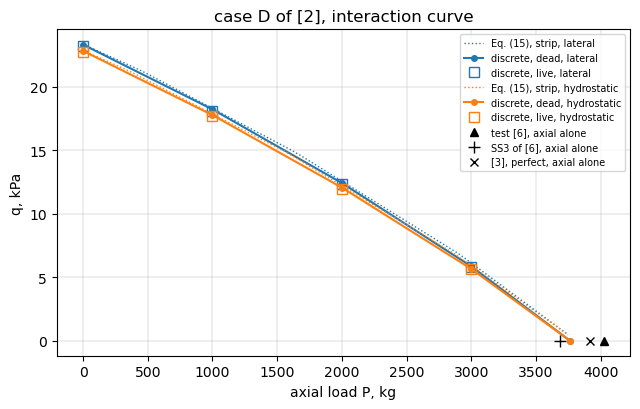

In [23]:
# Shen, Zhou and Chen (1993), Table 1 (p. 56), last row (= case D of [2]), kg
SHEN_D = dict(P_exp=4025., P_post=2250., r_ss3=1.09, r_c4=0.62, P_cr=3918., P_low=2783.)
# Singer and Abramovich (1979) [6], Table 2 (p. 764), shell AB6, kg, and the printed linearities rho
SINGER_AB6 = dict(SS3=(3687., 1.09), SS4=(5425., 0.74), C4=(6489., 0.62), sp=(5340., 0.75))
KPA_D = KGF*1e3  # kPa per kg/mm^2
dd = shells['D']
kgD = 2*np.pi*dd['R']  # kg per unit axial force per unit circumference
PD = (0., 1000., 2000., 3000.)  # kg
WsD = (dd['A'], dd['e'], dd['I'] + dd['A']*dd['e']**2)
PsD = (dd['ts']*dd['Hs'], dd['Hs']/2, dd['ts']*dd['Hs']**3/3)
meshD = (37, 16, 5)
t0 = time.time()
resD = {}
for msh in [(25, 12, 4), meshD]:
    modelD = build(dd, msh)
    resD[(msh, 'dead', 0., 'lateral')] = (modelD,) + scan_pressure(modelD, 0, 0.)
    resD[(msh, 'live', 0., 'lateral')] = (modelD,) + scan_pressure_live(
        modelD, 0, 0., resD[(msh, 'dead', 0., 'lateral')][2])
for P in PD:
    for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
        if (meshD, 'dead', P, load) not in resD:
            resD[(meshD, 'dead', P, load)] = (modelD,) + scan_pressure(modelD, kappa, P/kgD)
            resD[(meshD, 'live', P, load)] = (modelD,) + scan_pressure_live(
                modelD, kappa, P/kgD, resD[(meshD, 'dead', P, load)][2])
print('%.0f s' % (time.time() - t0))


def qmn(key):
    out, n = resD[key][1:]
    return out[n][0], out[n][1], n


rows = []
for kind in ('dead', 'live'):
    q1, q2 = (qmn((msh, kind, 0., 'lateral')) for msh in [(25, 12, 4), meshD])
    rows.append([kind, '%.3f (%d, %d)' % (KPA_D*q1[0], *q1[1:]), '%.3f (%d, %d)' % (KPA_D*q2[0], *q2[1:]),
                 '%+.2f %%' % pct(q2[0], q1[0])])
table(['case D, lateral, P = 0', 'mesh (25, 12, 4), kPa', 'mesh (37, 16, 5), kPa', 'change'], rows)

rows = []
for P in PD:
    for load, kappa in (('lateral', 0), ('hydrostatic', 1)):
        smS = smeared_q(dd, *PsD, dd['J'], kappa, P/kgD)
        smW = smeared_q(dd, *WsD, dd['J'], kappa, P/kgD)
        qd, ql = qmn((meshD, 'dead', P, load)), qmn((meshD, 'live', P, load))
        rows.append(['%.0f' % P, load, '%.2f %s' % (KPA_D*smW[0], smW[1]), '%.2f' % (KPA_D*smS[0]),
                     '%.2f (%d, %d)' % (KPA_D*qd[0], *qd[1:]), '**%+.1f %%**' % pct(qd[0], smS[0]),
                     '%.2f (%d, %d)' % (KPA_D*ql[0], *ql[1:]), '%+.2f %%' % pct(ql[0], qd[0])])
table(['P, kg', 'pressure', 'Eq. (15), section of [2], kPa (m, n)', 'Eq. (15), strip, matched J',
       'discrete, dead (m, n)', 'gap', 'discrete, live (m, n)', 'live vs dead'], rows)

Nd = res[('D', 'matched')][1][res[('D', 'matched')][2]][0]
table(['[6], Table 2', 'P, kg', 'test/P', 'rho of [6]', 'ratio of [3], Table 1'],
      [[k, '%.0f' % P, '%.3f' % (SHEN_D['P_exp']/P), r,
        {'SS3': SHEN_D['r_ss3'], 'C4': SHEN_D['r_c4']}.get(k, '-')] for k, (P, r) in SINGER_AB6.items()])
ax_refs = [('test, [6]', SHEN_D['P_exp']),
           ('linear smeared theory, SS3, [6]', SINGER_AB6['SS3'][0]),
           ('linear smeared theory, SS4, [6]', SINGER_AB6['SS4'][0]),
           ('linear smeared theory, C4 (clamped), [6]', SINGER_AB6['C4'][0]),
           ('equivalent end springs, [6]', SINGER_AB6['sp'][0]),
           ('perfect shell, [3]', SHEN_D['P_cr']),
           ('smeared, nonlinear, [2]', kgD*POORVEIS_T2['D'][1]),
           ('discrete, nonlinear, [2]', kgD*POORVEIS_T2['D'][2]),
           ('Eq. (15), section of [2]', kgD*dd['sm_W'][0]),
           ('Eq. (15), strip, matched J', kgD*dd['sm_P_J'][0])]
table(['axial compression alone', 'P, kg', 'discrete (%.0f kg) vs' % (kgD*Nd)],
      [[name, '%.0f' % P, '%+.1f %%' % pct(kgD*Nd, P)] for name, P in ax_refs])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
Ps = np.linspace(0., kgD*dd['sm_P_J'][0], 60)
for load, kappa, c in (('lateral', 0, 'C0'), ('hydrostatic', 1, 'C1')):
    qs = np.array([smeared_q(dd, *PsD, dd['J'], kappa, P/kgD)[0] for P in Ps])
    ok = qs > 0
    ax.plot(Ps[ok], KPA_D*qs[ok], c + ':', lw=1, label='Eq. (15), strip, %s' % load)
    ax.plot(list(PD) + [kgD*Nd], [KPA_D*qmn((meshD, 'dead', P, load))[0] for P in PD] + [0.], c + 'o-', ms=4,
            label='discrete, dead, %s' % load)
    ax.plot(PD, [KPA_D*qmn((meshD, 'live', P, load))[0] for P in PD], c + 's', mfc='none', ms=7,
            label='discrete, live, %s' % load)
ax.plot([SHEN_D['P_exp']], [0.], 'k^', label='test [6], axial alone')
ax.plot([SINGER_AB6['SS3'][0]], [0.], 'k+', ms=9, label='SS3 of [6], axial alone')
ax.plot([SHEN_D['P_cr']], [0.], 'kx', label='[3], perfect, axial alone')
ax.set_xlabel('axial load P, kg')
ax.set_ylabel('q, kPa')
ax.set_title('case D of [2], interaction curve')
ax.grid(True, lw=0.3)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Case B** (`card1966_stiffened_cylinder_buckling.ipynb`, cylinder 1, SS,
membrane): this repository gives 1144 lb/in (20.43 kg/mm) with the section
of Card and Jones, where [2] reports 20.39 kg/mm smeared and 21.45 kg/mm
discrete (+5.2 %); 1 lb/in = 0.017858 kg/mm.

## Discussion

- **Input.** Equation (15) of [4] with the stringer properties of Table 1 of
  [1] reproduces the SS3 loads of [1] within 0.14 % for the five shells, so
  the section, the material and the number of stringers are read as Weller
  and Singer read them. The stringers are rectangles; their torsion constant
  $I_{t1}$ is that of the rectangle.
- **General instability (AS-34, AS-35, case D; $\theta = 0.47$, $b/\sqrt{Rh}
  = 1.6$).** The discrete model buckles in the general mode $(m, n) = (1,
  11)$ of the smeared theory, 1.2 % below equation (15) for the same
  plate strip with the matched twisting stiffness (2.1 to 2.2 % with the
  plate twisting stiffness). This is the discreteness gap at this spacing: one
  to two percent. Against the SS3 loads of [1] (for the rectangle) the
  discrete model is 0.6 % below; the overlap of the strip with the skin and its
  centroid at $H_s/2$ instead of $e_1$ make equation (15) for the strip 0.8 %
  higher than for the rectangle. The tests are at 82 and 84 % of SS3
  (the "linearity" of [1]), +18 and +22 % from the discrete model: the
  difference between test and theory is the imperfection sensitivity
  discussed in [1], not the discreteness of the stringers.
- **Panel instability (AS-27; $\theta = 0.79$ to 0.81).** The lowest mode of
  the discrete model is local: the skin between the stringers buckles with
  one half-wave per bay ($n = n_s/2 = 28$) and nine axial half-waves, at
  4.13 to 4.54 kg/mm, 18.5 to 25.6 % below the general instability of the smeared
  theory, which cannot represent this mode. This is the case of a large
  "gap" in the literature: Poorveis and Kabir found their discrete value 30 %
  below their smeared one for AS-27M2 and attributed it to panel instability
  ([2], p. 119). The discrete model of this notebook is +4.2 % from the
  test of AS-27M2 and +6.8 % from the discrete value of [2] (whose model
  includes the nonlinear pre-buckling deformation and transverse shear); the
  three tests of the nearly equal AS-27 shells scatter from 4.36 to 5.17
  kg/mm, and the model is -13.0, +4.2 and -13.9 % from them. The local load is almost
  independent of the twisting stiffness of the stringers (+0.9 to +1.1 % from
  matched to plate $J$), whereas the general-instability load of the smeared
  theory rises by 44 % with the plate twisting stiffness: with an unmatched
  plate strip the apparent gap would be 43 to 48 %. In the model the skin
  bay is the whole pitch $b = 13.5$ mm, the stringer root being a line; the
  real stringers are 1.53 mm wide (11 % of the pitch), which leaves a
  narrower skin panel and would raise the local load (a plate-buckling load
  scales with the inverse square of the panel width: $(13.53/12.0)^2 = 1.27$
  for the free width, an estimate, not a computed value).
- **Case D of [2]** (85 stringers, from Shen, Zhou and Chen [3]): discrete
  4.988 kg/mm, -1.3 % from equation (15) for the same strip, -6.5 %
  from the test of Singer and Abramovich (1979)
  cited by [3] and [2]. Poorveis and Kabir give the discrete
  value 1.5 % *above* the smeared one (5.450 and 5.370 kg/mm); their smeared
  nonlinear value is 7 % above equation (15) with their own section (5.018
  kg/mm), so the difference between their two models and the linear theory
  is larger than the discreteness effect found here. Case B of [2] (cylinder
  1 of Card and Jones, discrete 5.2 % above smeared in [2]): both
  implementations of the card1966 notebooks give the discrete simply
  supported membrane load within 0.1 % of the smeared $\bar{N}_s$.
- **Case C of [2] (shell DUD-8 of [5], external pressure; $\theta =
  0.48$).** Every loading buckles in the general mode $(m, n) = (1, 11)$ of
  the smeared theory (the tests: $n = 10$ and 9), and the discrete model is
  within 0.4 % of equation (15) for the same strip (matched $J$; 0.3 % with
  the plate $J$): the stringers carry no hoop force, so the pressure part of
  the buckling load has no discreteness gap at this spacing, whereas the
  axial run 4 of the same shell gives -1.3 %, as AS-34 and AS-35. With the
  section of [2], equation (15) is within 0.6 to 0.8 % (lateral) and -0.7 to
  -0.9 % (hydrostatic) of the SS3 predictions of [5] (+2.7 % for run 4), so
  these do not tell which pressure [5] computed; the end load of hydrostatic
  pressure lowers $q$ by 1.5 %. The discrete model (matched $J$) is -0.6,
  -1.2 and -2.5 % (lateral) or -2.1, -2.7 and -3.9 % (hydrostatic) from the
  tests of runs 1 to 3 (13.55, 12.3, 11.10 kPa) and +5.8 % from the axial
  test. The tests are at 1.02 to 1.04 of the SS3 predictions of [5] (Table
  4), whereas the actual ends, between SS3 and SS4, give 14.6, 14.2 and 13.3
  kPa with the equivalent springs of [5]: the agreement of the SS3 model with
  the tests is a balance of a stiffer end restraint against imperfections,
  not a check of the model. The twisting stiffness enters directly: the plate
  $J$ raises $q$ by 6.4 %. The nonlinear values of [2] bracket the tests:
  smeared -2.9 and -1.4 %, discrete +9.2 and +14.4 %, the discrete 12.5 and
  16.0 % above the smeared, whereas here discrete and smeared agree; the
  discrete model here is 9.0 to 16.0 % below the discrete values of [2].
- **Live pressure (case C).** The load stiffness of the follower pressure
  is symmetric here, its skew part being $5 \times 10^{-17}$ of its norm for the matrices of a harmonic (ends with $w = 0$, cyclic sector edges; the matrix of the sector alone, whose edges are free, has a skew part of 0.46, which the cyclic constraints cancel), as the condition of
  Hibbitt (1979) and Schweizerhof and Ramm (1984, Table 2) says for a
  uniform pressure on a surface whose edges have $w = 0$ or a zero normal
  displacement; the unsymmetric solver returns the same real eigenvalues.
  The live pressure lowers $q$ by 0.78 to 0.79 % for every run, lateral and
  hydrostatic, in the same mode $(m, n) = (1, 11)$: runs 1 to 3 13.36, 12.05, 10.74 kPa
  (lateral) and 13.17, 11.88, 10.58 kPa (hydrostatic), -1.4, -2.0 and -3.2 % (lateral) or -2.8, -3.4 and -4.6 % (hydrostatic) from the tests. The live
  lateral values are within 0.5 % of the SS3 predictions of [5], the live
  hydrostatic ones -1.0 to -1.1 %. Neither [2] nor [5] says which of the four
  variants it computed; they span 2.3 %, less than the effect of the end
  restraint (the equivalent springs of [5] give 10 to 24 % more than SS3).
- **Interaction curve of DUD-8.** Up to $P = 8$ kN the discrete model
  follows equation (15) for the same strip within 0.6 %; at $P = 16$ and 24
  kN (7.85 and 4.64 kPa lateral, 7.71 and 4.55 kPa hydrostatic), where the mode becomes $(1, 10)$, the gap is -0.4 and -2.2 %, against
  -1.3 % under axial compression alone. Divided by its own values under
  pressure alone and axial load alone, the discrete curve lies on the
  perfect-shell curve of Shen, Zhou and Chen [3] (Fig. 3(a)) within the
  reading precision (0.01), slightly outside the straight line $R_x + R_y =
  1$, and so does equation (15): the shape of the interaction curve of this
  shell is the same in the linear smeared theory, the discrete model and the
  boundary-layer theory of [3]. The tests of [5], as plotted by [3], lie on
  the curves, except the axial test ($R_x = 0.93$).
- **Case D under combined loading.** Neither [2] nor [3] gives a pressure or
  combined-loading value for this shell; the interaction curve here is a
  prediction. Under pressure alone the discrete model buckles in $(1, 14)$;
  at $P = 0$, 1000, 2000 and 3000 kg (dead pressure) 23.31, 18.21, 12.42 and 5.86 kPa lateral and
  22.81, 17.76, 12.06 and 5.66 kPa hydrostatic, the mode going to $n = 13$, 12 and 11 and the gap
  against equation (15) for the same strip -0.2, -0.4, -1.2 and -4.2 % as the axial share grows
  (axial compression alone -1.3 %); the live pressure lowers $q$ by 0.47 to
  0.76 %. Axial compression alone, 3764 kg: -6.5 % from the test of Singer
  and Abramovich (4025 kg), -3.9 % from the perfect shell of [3] (3918
  kg), +1.9 % from the SS3 prediction derived from the ratio 1.09 of [3]
  (3693 kg) and -8.5 % from the discrete value of [2]. The C4 (clamped)
  prediction derived from the ratio 0.62, 6492 kg, is 76 % above the SS3
  one; the ends of the test were "close to clamped" ([3], p. 55).
- **Summary of the gap.** With closely spaced stringers that buckle in a
  general mode, the discrete model is 1 to 2 % below the smeared theory of
  the same section; when the skin between the stringers is prone to panel
  buckling ($\theta > 0.64$), the discrete model buckles locally, 19 to 26 %
  below the smeared general instability. Weller and Singer write that the
  discreteness "has also been studied and found to be negligible for closely
  spaced stiffened cylinders except for unusual geometries" (p. 722); the
  AS-27 shells are such a geometry by design.
- **The panels implementation of this case**
  (`panels/notebooks/weller1977_blade_cylinder_buckling.ipynb`: half cylinder
  of curved Sanders skin panels and `plate_clpt_gl` blades, the same strips,
  matched and plate $J$, 20 x 10 x 5 terms) gives the same modes and agrees
  within 0.7 %: AS-27M1/M2/M3 4.131, 4.536, 4.449 kg/mm (here 4.134, 4.540,
  4.453); AS-34 and AS-35 4.504 and 4.448 (here 4.526 and 4.470); case D
  4.957 (whole cylinder; here 4.988). Its gaps are -1.7 % (AS-34, AS-35) and
  -1.9 % (case D) with the matched $J$, -18.6 to -25.6 % for the AS-27 shells.
  Case C (external pressure, 84 stringers, half cylinder, 24 x 10 x 5 terms):
  runs 1 to 3 13.41, 12.09, 10.76 kPa lateral and 13.21, 11.91, 10.60 kPa
  hydrostatic (here 13.47, 12.15, 10.83 and 13.27, 11.97, 10.67), gaps -0.1
  to -0.6 %; run 4 33.69 kN (here 33.84 kN).
  Live pressure (case C): 13.30, 11.99, 10.68 kPa lateral and 13.11, 11.81,
  10.52 kPa hydrostatic (here 13.36, 12.05, 10.74 and 13.17, 11.88,
  10.58), the same -0.78 to -0.79 % from the dead pressure; $P = 16$ and 24
  kN: 7.78 and 4.57 kPa lateral, 7.64 and 4.48 kPa hydrostatic (here 7.85,
  4.64, 7.71, 4.55). Case D under combined loading, lateral, $P = 0$ to 3000
  kg: dead 23.15, 18.06, 12.25, 5.68 kPa, live 23.04, 17.96, 12.17, 5.64 kPa
  (here 23.31, 18.21, 12.42, 5.86 and 23.19, 18.11, 12.34, 5.82): 0.7 to
  1.4 % apart up to 2000 kg and 3.2 % at 3000 kg, where its gap is -7.1 % (here
  -4.2 %), as for the axial load alone (-1.9 %, here -1.3 %).